# 14 — C1–C3 VR summary: DATA와 MC (4mu)

**Mu isolation × |Δφ|** 평면에서 저장된 **C1–C3** 후보를 왼쪽부터 1×3으로 비교한다.
질량 선택은 **Mjj≥150 GeV**, nominal WP는 **(mu iso, |Δφ|)=(0.30, 2.6)**이다.
DATA와 MC의 분포, 관측 A·ABCD 예측, κ·오차, 1D/2D scan, 배경 조성·유효 통계와
**전체 120개 신호 가설의 각 ABCD 영역 S/B**를 함께 정리한다.
후보를 고른 좁은 탐색 구간과 구분하여, 진단용 1D 축은 **iso 0–1, Δφ 0–π**,
2D 지도는 같은 native 경계의 **10×14=140점**을 사용한다. **Nominal MC SR**도 별도 참고 블록으로 보여준다.

원본 coffea에서 재계산하고, 2026-10-15에 저장한 후보 수치·검산표와 비교한다.
`Restart → Run All`로 실행한다. 계산·플롯 함수는 내장되어 있으며 임시 코드나 다른 노트북 실행에 의존하지 않는다.
후보들은 서로 사건이 겹치는 **검토용 대안**이다. 이 노트북 정리가 최종 VR/WP 채택을 뜻하지 않는다.

In [1]:
from pathlib import Path
import ast
import gc
import hashlib
import json
import sys
from datetime import datetime, timezone

SIDM_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if p.name == "sidm"), None)
if SIDM_DIR is None:
    raise RuntimeError("Run this notebook from within the sidm repository.")
if str(SIDM_DIR.parent) not in sys.path:
    sys.path.insert(0, str(SIDM_DIR.parent))
NOTEBOOK_DIR = SIDM_DIR / "studies" / "ABCD_plane_summary"
STUDIES_DIR = SIDM_DIR / "studies"

# Import coffea/pyarrow before registering NumPy 2 pickle compatibility aliases.
import coffea.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
if int(np.__version__.split(".")[0]) < 2:
    import numpy.core as _numpy_core
    import numpy.core.multiarray as _numpy_multiarray
    import numpy.core.numeric as _numpy_numeric
    sys.modules.setdefault("numpy._core", _numpy_core)
    sys.modules.setdefault("numpy._core.multiarray", _numpy_multiarray)
    sys.modules.setdefault("numpy._core.numeric", _numpy_numeric)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "pdf.fonttype": 42})
pd.set_option("display.max_columns", 20)

import copy
import yaml
from IPython.display import Markdown
plt.rcParams.update({"figure.max_open_warning": 0})


## 1. 후보 정의

| 후보 | LJ0 / LJ1 displacement | Partner isolation | 선택된 plateau: mu iso × Δφ |
|---|---|---|---|
| C1 | P / any | 0.2≤iso<1 | [0.25, 0.3] × [2.4, 2.6, 2.7] |
| C2 | P / any | 0.15≤iso<1 | [0.25, 0.3] × [2.6, 2.7] |
| C3 | P / P | 0.15≤iso<1 | [0.25, 0.3] × [2.6, 2.7] |

LJ0/LJ1은 pT leading/subleading mu-LJ다. 두 Mu P 조건은 max pixel hits>2이다. 선택 후 LJ를 재정렬하지 않는다.

두 채널은 동일한 C1–C3 정의와 nominal WP·공통 plateau를 사용한다.

`any`는 해당 displacement cut을 적용하지 않는다는 뜻이다. 기존 P/D 수치 경계는 고정한다.
평면의 isolation은 LJ0, partner isolation은 LJ1에 적용한다. 별도 Δφ event precut은 없다.
ABCD는 A=low iso/high Δφ, B=high/high, C=low/low, D=high/low이며, $\hat A=BC/D$, $\kappa=A/(BC/D)$를 사용한다.
Isolation·mass underflow는 제외하고 displacement·Δφ flow는 유지한다. 상한이 없는 선택은 overflow도 포함한다.

In [2]:
TOPOLOGY = '4mu'
NOTEBOOK_NAME = '14_MuIso_DPhi_4mu_Displacement_VR_comparison.ipynb'
OUTPUT_DIR = NOTEBOOK_DIR / '14_C1_C3_4mu_VR_summary_outputs'
CANDIDATE_DIR = NOTEBOOK_DIR / 'PDany_plane_mass_scan_outputs' / 'synchronized_candidates'
CONFIG = {
    'topology': TOPOLOGY, 'group': 'high', 'candidate_order': ['C1', 'C2', 'C3'],
    'output_dir': OUTPUT_DIR,
    'definitions_path': CANDIDATE_DIR / 'selected_synchronized_definitions.json',
    'all12_path': CANDIDATE_DIR / 'selected_synchronized_all12.csv',
    'audit_path': CANDIDATE_DIR / 'audit_synchronized_points.csv',
    'sr_reference_dir': NOTEBOOK_DIR / '12_Optimized_ABCD_4mu_comparison_outputs',
    'bkg_dir': NOTEBOOK_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_bkg_merged_samples_v1',
    'signal_dir': NOTEBOOK_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_signal_merged_samples_v1',
    'data_dir': NOTEBOOK_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_data_merged_samples_v1',
    'current_hist': 'abcd6d_' + TOPOLOGY,
    'expected_current_channel': 'abcd6d_inclusive_' + TOPOLOGY + '_dxySpread_cosAlpha_mu_veto_eHEM',
    'mass_min': 150.0, 'mass_max': None,
    'closure_band': (.9, 1.1), 'min_neff': 10., 'purity_limit': .10,
}
print('채널:', TOPOLOGY, '| 후보:', CONFIG['candidate_order'], '| 출력:', OUTPUT_DIR)


채널: 4mu | 후보: ['C1', 'C2', 'C3'] | 출력: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/14_C1_C3_4mu_VR_summary_outputs


## 2. 순도·통계와 회귀 검증

- 200–1000 GeV의 **2Mu2E 60개 + 4Mu 60개**를 각 분석 채널에서 개별 평가한다. 서로 다른 가설의 신호량을 합산하지 않는다.
- 각 WP에서 모든 신호 가설·ABCD 영역이 **$S/B_{MC}<0.10$**이어야 DATA closure를 표시한다. 배경 분모가 양수이고 유효한지도 검사한다.
- **DD signal leakage veto는 사용하지 않는다.** S/B 통과는 MC 중앙값 기준이며, 오차를 포함한 상한이 10% 아래라는 의미는 아니다.
- 저장된 12점은 mu iso `{0.25,0.30,0.40,0.50}` × Δφ `{2.4,2.6,2.7}`이다. 선택된 plateau는 정의 JSON에 명시한 부분집합이다.
- 표시용 스캔은 05–12와 같은 iso 0–1, Δφ 0–π 범위의 native 경계를 사용한다. 1D는 각각 10점·14점, 2D는 140점이다. 0 경계는 퇴화한 사분면을 만들므로 기존처럼 계산하지 않고 축만 0부터 표시한다. π 경계의 undefined/low-stat 값은 그대로 표시한다.
- 넓어진 범위에서 후보를 다시 고르지 않는다. Nominal WP·plateau·기존 12점 회귀 검증은 그대로 유지한다.
- DATA 후보 기준은 `0.9≤κ≤1.1`, `σκ≤0.2`, 각 ABCD count≥10이며, plateau의 `max κ−min κ≤0.1`이다. **MC closure를 이 DATA 기준으로 가리지 않는다.**
- MC 및 DATA의 κ 오차는 기존 sumw² delta method를 유지한다. MC Neff<10은 진단 표시이며 추가 veto가 아니다.
- 후보 3개×12점의 DATA ABCD·κ·오차, MC κ·Neff, 최대 S/B와 최악 신호/영역을 저장 CSV와 비교한다. 별도 audit의 MC ABCD sumw/sumw²·κ 오차도 비교한다.

이미 관찰한 DATA에서 찾은 plateau이며 인접점과 후보 사이에 사건이 겹친다. 독립적인 검증 표본이나 확정된 분석 선택으로 해석하지 않는다.

In [3]:
# 기존 histogram schema·통계·flow-aware helper를 필요한 범위만 유지한다.
COMPARISON_VARIABLES = ("iso0", "iso1", "disp0", "disp1", "abs_dphi", "ljlj_mass")

def _comparison_json(value):
    def convert(item):
        if isinstance(item, (set, frozenset)):
            return sorted(item, key=str)
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, np.ndarray):
            return item.tolist()
        if isinstance(item, Path):
            return str(item)
        return str(item)
    return json.dumps(value, sort_keys=True, default=convert)

def _comparison_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def _comparison_group(sample):
    if sample.startswith("QCD_"):
        return "QCD"
    if sample.startswith("DYJetsTo"):
        return "DY"
    if sample == "TTJets":
        return "TTJets"
    if sample in {"WW", "WZ", "ZZ"}:
        return "Diboson"
    raise ValueError(f"Unexpected MC background sample: {sample}")

def _comparison_split(edges, threshold):
    matches = np.flatnonzero(np.isclose(edges, float(threshold), rtol=0, atol=1e-12))
    if len(matches) != 1:
        raise ValueError(f"A requested threshold is not a unique stored bin edge: {threshold}")
    return int(matches[0]) + 1

def _comparison_validate_arrays(values, variances):
    if variances is None or values.shape != variances.shape:
        raise ValueError("Weighted values and sumw2 must have the same shape.")
    if not np.isfinite(values).all() or not np.isfinite(variances).all():
        raise ValueError("The selected histogram contains nonfinite weights or sumw2.")
    if np.any(variances < 0):
        raise ValueError("The selected histogram contains negative sumw2.")

def _comparison_plane(values, variances, xedges, yedges):
    values = np.asarray(values, dtype=float).copy()
    variances = np.asarray(variances, dtype=float).copy()
    _comparison_validate_arrays(values, variances)
    xedges = np.asarray(xedges, dtype=float).copy()
    yedges = np.asarray(yedges, dtype=float).copy()
    if values.shape != (len(xedges) + 1, len(yedges) + 1):
        raise ValueError("The 2D plane must contain both numeric flow bins on each axis.")
    return dict(values=values, variances=variances, xedges=xedges, yedges=yedges)

def _comparison_add(target, incoming, component):
    if target is None:
        target = _comparison_plane(incoming["values"], incoming["variances"],
                                   incoming["xedges"], incoming["yedges"])
        target["values"][:] = 0
        target["variances"][:] = 0
        target["components"] = {}
    if not all(np.array_equal(target[key], incoming[key]) for key in ("xedges", "yedges")):
        raise ValueError("Cannot combine planes with different numeric bin edges.")
    target["values"] += incoming["values"]
    target["variances"] += incoming["variances"]
    if component not in target["components"]:
        target["components"][component] = dict(
            values=np.zeros_like(incoming["values"]),
            variances=np.zeros_like(incoming["variances"]))
    target["components"][component]["values"] += incoming["values"]
    target["components"][component]["variances"] += incoming["variances"]
    return target

def _comparison_payload(path, source):
    loaded = coffea.util.load(path)
    outputs = loaded.get("out", loaded) if isinstance(loaded, dict) else None
    if outputs is None or set(outputs) != {path.stem}:
        raise ValueError(f"The payload sample identity does not match its file name: {path}")
    payload = outputs[path.stem]
    metadata = payload.get("metadata", {})
    if set(metadata.get("is_data", ())) != {False}:
        raise ValueError(f"Only explicitly identified MC backgrounds may be loaded: {path}")
    if set(metadata.get("unweighted_hist", ())) != {False}:
        raise ValueError(f"A weighted production is required: {path}")
    if {str(value) for value in metadata.get("year", ())} != {"2018"}:
        raise ValueError(f"The payload must have a unique 2018 year: {path}")
    if "hists" not in payload or "cutflow" not in payload:
        raise ValueError(f"Missing histograms or production cutflows: {path}")
    return loaded, payload

def _comparison_validate_hist(histogram, path):
    if histogram.storage_type.__name__ != "Weight":
        raise ValueError(f"Weight storage is required: {path}")
    for axis in histogram.axes:
        if not axis.traits.discrete and not (axis.traits.underflow and axis.traits.overflow):
            raise ValueError(f"Numeric flow bins are required: {path}/{axis.name}")

def _comparison_current_cube(payload, path, config):
    expected_hists = {f"abcd6d_{topology}" for topology in ("2mu2e", "4mu")} | {
        f"abcd6d_ref_{topology}_{pair}" for topology in ("2mu2e", "4mu")
        for pair in ("iso0_vs_iso1", "iso0_vs_abs_dphi", "disp0_vs_disp1")}
    if set(payload["hists"]) != expected_hists:
        raise ValueError(f"The current 6D campaign histogram schema differs: {path}")
    histogram = payload["hists"][config["current_hist"]]
    _comparison_validate_hist(histogram, path)
    if tuple(axis.name for axis in histogram.axes) != ("channel",) + COMPARISON_VARIABLES:
        raise ValueError(f"Current 6D axis order mismatch: {path}")
    channel_axis = histogram.axes["channel"]
    if (list(channel_axis) != [config["expected_current_channel"]]
            or not channel_axis.traits.discrete
            or channel_axis.traits.underflow or channel_axis.traits.overflow):
        raise ValueError(f"Current topology channel identity/flow mismatch: {path}")
    expected_edges = {
        "iso0": [0, .05, .1, .15, .2, .25, .3, .4, .5, .75, 1, 2, 5],
        "iso1": [0, .05, .1, .15, .2, .25, .3, .4, .5, .75, 1, 2, 5],
        "disp0": np.arange(-.5, 12, 1),
        "disp1": np.arange(-.5, 10 if config["topology"] == "2mu2e" else 12, 1),
        "abs_dphi": [0, .5, 1, 1.5, 2, 2.2, 2.4, 2.6, 2.7, 2.8, 2.9, 3, 3.05, 3.1, np.pi],
        "ljlj_mass": [0, 50, 100, 150, 200, 300, 400, 600, 800, 1000, 1500, 2500],
    }
    edges = {name: np.asarray(histogram.axes[name].edges, dtype=float) for name in COMPARISON_VARIABLES}
    for name in COMPARISON_VARIABLES:
        expected = np.asarray(expected_edges[name], dtype=float)
        if edges[name].shape != expected.shape or not np.allclose(edges[name], expected, rtol=0, atol=1e-12):
            raise ValueError(f"Current campaign stored bin edges differ: {path}/{name}")
    weights, variances = histogram.values(flow=True), histogram.variances(flow=True)
    expected_shape = (1,) + tuple(len(edges[name]) + 1 for name in COMPARISON_VARIABLES)
    if variances is None or weights.shape != expected_shape or variances.shape != expected_shape:
        raise ValueError(f"Current 6D weighted values/variance shape mismatch: {path}")
    return weights[0], variances[0], edges

def plane_statistics(plane, tx, ty, include_iso_underflow=False, min_neff=10.):
    """Match notebook 10 prediction/closure conventions; annotate edge cases.

    B, C and D are total background sums. No negative sumw is clipped. The
    relative-error formula intentionally reproduces notebook 10's zero-sideband
    uncertainty convention; its mathematical limitation is flagged in status.
    """
    regions = _comparison_regions(plane, tx, ty, include_iso_underflow)
    row = dict(tx=float(tx), ty=float(ty), pred=np.nan, pred_error=np.nan,
               kappa=np.nan, kappa_error=np.nan, pull=np.nan,
               status="UNDEFINED_PREDICTION", kappa_status="UNDEFINED_PREDICTION")
    for name, item in regions.items():
        row.update({name: item["value"], "var_" + name: item["variance"],
                    name + "_error": item["error"], "neff_" + name: item["neff"]})
    neffs = np.array([regions[name]["neff"] for name in "ABCD"])
    row.update(neff_min=float(np.min(neffs)), min_neff=float(np.min(neffs)),
               min_sideband_neff=float(np.min(neffs[1:])),
               low_stat=bool(not np.all(np.isfinite(neffs) & (neffs >= min_neff))))
    a, b, c, d = (regions[name]["value"] for name in "ABCD")
    ea, eb, ec, ed = (regions[name]["error"] for name in "ABCD")
    if d <= 0 or not np.all(np.isfinite([b, eb, c, ec, d, ed])):
        row["status"] = "NONPOSITIVE_D_OR_NONFINITE_SIDEBAND"
        row["kappa_status"] = row["status"]
        return row
    pred = b * c / d
    terms = [(eb / b)**2 if b else 0., (ec / c)**2 if c else 0., (ed / d)**2]
    epred = abs(pred) * np.sqrt(sum(terms))
    row.update(pred=pred, pred_error=epred)
    if b == 0 or c == 0:
        row["status"] = "ZERO_SIDEBAND_LEGACY_ZERO_PREDICTION_ERROR"
    elif b < 0 or c < 0:
        row["status"] = "NEGATIVE_SIDEBAND_RETAINED"
    else:
        row["status"] = "LOW_STAT_SIDEBAND" if not np.all(
            np.isfinite(neffs[1:]) & (neffs[1:] >= min_neff)) else "OK"
    if np.isfinite(a) and pred > 0:
        row["kappa"] = a / pred
        if a > 0:
            row["kappa_error"] = abs(row["kappa"]) * np.sqrt((ea / a)**2 + (epred / pred)**2)
            row["kappa_status"] = "LOW_STAT" if row["low_stat"] else "OK"
        else:
            row["kappa_status"] = "NONPOSITIVE_A_LEGACY_KAPPA_ERROR_UNDEFINED"
    else:
        row["kappa_status"] = "NONPOSITIVE_PREDICTION_OR_NONFINITE_A"
    if np.isfinite(a) and ea**2 + epred**2 > 0:
        row["pull"] = (a - pred) / np.sqrt(ea**2 + epred**2)
    return row

def _extension_coarsen_regular(plane, ex, ey, key):
    """Exclude flow and regular bins outside the common support; never fold tails."""
    native_x, native_y = plane["xedges"], plane["yedges"]
    values = np.asarray(plane[key], dtype=float)[1:-1, 1:-1]
    selected_x = (native_x[:-1] >= ex[0] - 1e-12) & (native_x[1:] <= ex[-1] + 1e-12)
    selected_y = (native_y[:-1] >= ey[0] - 1e-12) & (native_y[1:] <= ey[-1] + 1e-12)
    low_x, low_y = native_x[:-1][selected_x].copy(), native_y[:-1][selected_y].copy()
    for edge in ex:
        low_x[np.isclose(low_x, edge, rtol=0, atol=1e-12)] = edge
    for edge in ey:
        low_y[np.isclose(low_y, edge, rtol=0, atol=1e-12)] = edge
    ix, iy = np.searchsorted(ex, low_x, side="right") - 1, np.searchsorted(ey, low_y, side="right") - 1
    xx, yy = np.meshgrid(ix, iy, indexing="ij")
    output = np.zeros((len(ex) - 1, len(ey) - 1), dtype=float)
    np.add.at(output, (xx.ravel(), yy.ravel()), values[np.ix_(selected_x, selected_y)].ravel())
    return output

def extension_correlations(plane, tx, ty, ex, ey, min_neff=10.):
    """Weighted Pearson in All/A/B/C/D at centers of shared coarsened bins."""
    regions = ("All", "A", "B", "C", "D")
    if plane is None:
        return [dict(region=region, correlation=np.nan, rho=np.nan, neff=np.nan,
                     status="GATE_BLOCKED", sumw=np.nan, sumw2=np.nan, negative_bins=np.nan,
                     display_binning=_comparison_json(dict(xedges=ex, yedges=ey)),
                     support="Native regular-bin support only; both plane flow axes excluded")
                for region in regions]
    values = _extension_coarsen_regular(plane, ex, ey, "values")
    variances = _extension_coarsen_regular(plane, ex, ey, "variances")
    negative_plane = dict(plane, values=(plane["values"] < 0).astype(float))
    native_negative = _extension_coarsen_regular(negative_plane, ex, ey, "values")
    xx, yy = np.broadcast_arrays(((ex[:-1] + ex[1:]) / 2)[:, None], ((ey[:-1] + ey[1:]) / 2)[None, :])
    xpass, ypass = xx < tx, yy >= ty
    masks = (np.ones(xx.shape, bool), xpass & ypass, ~xpass & ypass, xpass & ~ypass, ~xpass & ~ypass)
    rows = []
    for region, mask in zip(regions, masks):
        weights, vars_ = values[mask], variances[mask]
        row = dict(region=region, correlation=np.nan, rho=np.nan, neff=np.nan, status="EMPTY",
                   sumw=float(weights.sum()), sumw2=float(vars_.sum()), negative_bins=int(np.sum(weights < 0)),
                   native_negative_bins=int(native_negative[mask].sum()),
                   display_binning=_comparison_json(dict(xedges=ex, yedges=ey)),
                   support="Native regular-bin support only; both plane flow axes excluded")
        if not np.isfinite(weights).all() or not np.isfinite(vars_).all() or np.any(vars_ < 0):
            row["status"] = "INVALID_WEIGHT_OR_VARIANCE"
        elif np.any(weights < 0) or row["native_negative_bins"] > 0:
            row["status"] = "NEGATIVE_BINS_NOT_A_PROBABILITY_DISTRIBUTION"
        elif row["sumw"] > 0 and row["sumw2"] > 0:
            row["neff"] = row["sumw"]**2 / row["sumw2"]
            xs, ys = xx[mask], yy[mask]
            mx, my = np.dot(weights, xs) / row["sumw"], np.dot(weights, ys) / row["sumw"]
            vx = np.dot(weights, (xs - mx)**2) / row["sumw"]
            vy = np.dot(weights, (ys - my)**2) / row["sumw"]
            if vx <= 0 or vy <= 0:
                row["status"] = "NO_SPREAD"
            else:
                rho = float(np.dot(weights, (xs - mx) * (ys - my)) / row["sumw"] / np.sqrt(vx * vy))
                if not np.isfinite(rho) or abs(rho) > 1 + 1e-10:
                    row["status"] = "INVALID_MOMENTS"
                else:
                    row.update(rho=float(np.clip(rho, -1, 1)), correlation=float(np.clip(rho, -1, 1)),
                               status="LOW_STAT" if row["neff"] < min_neff else "OK")
        elif row["sumw"] > 0:
            row["status"] = "ZERO_VARIANCE_UNSUPPORTED"
        rows.append(row)
    return rows

def _extension_data_payload(path):
    """Validate DATA identity without inspecting any DATA SR selection or values."""
    loaded = coffea.util.load(path)
    outputs = loaded.get("out", loaded) if isinstance(loaded, dict) else None
    if outputs is None or set(outputs) != {path.stem}:
        raise ValueError(f"DATA payload sample identity mismatch: {path}")
    payload = outputs[path.stem]
    metadata = payload.get("metadata", {})
    if set(metadata.get("is_data", [])) != {True}:
        raise ValueError(f"Explicit DATA metadata are required: {path}")
    if set(metadata.get("unweighted_hist", [])) != {False}:
        raise ValueError(f"Expected weighted DATA storage configuration: {path}")
    if {str(value) for value in metadata.get("year", [])} != {"2018"}:
        raise ValueError(f"Expected unique 2018 DATA metadata: {path}")
    return loaded, payload

def _extension_blank_statistics(tx, ty, reason="GATE_BLOCKED"):
    row = dict(tx=float(tx), ty=float(ty), pred=np.nan, pred_error=np.nan,
               kappa=np.nan, kappa_error=np.nan, pull=np.nan, neff_min=np.nan, min_neff=np.nan,
               min_sideband_neff=np.nan, low_stat=True, status=reason, kappa_status=reason)
    for region in "ABCD":
        row.update({region: np.nan, "var_" + region: np.nan, region + "_error": np.nan, "neff_" + region: np.nan})
    return row

def _angle_regions(plane, tx, ty, include_iso_underflow=False):
    """A=low isolation/high angle; retain both angle flows and exclude iso UF."""
    if include_iso_underflow:
        raise ValueError("This plane comparison excludes isolation underflow in every ABCD region.")
    ix = _comparison_split(plane["xedges"], tx)
    iy = _comparison_split(plane["yedges"], ty)
    slices = {"A": (slice(1, ix), slice(iy, None)),
              "B": (slice(ix, None), slice(iy, None)),
              "C": (slice(1, ix), slice(None, iy)),
              "D": (slice(ix, None), slice(None, iy))}
    result = {}
    for region, index in slices.items():
        value = float(plane["values"][index].sum())
        variance = float(plane["variances"][index].sum())
        result[region] = dict(value=value, variance=variance, error=np.sqrt(variance),
                              neff=value**2 / variance if variance > 0 else np.nan)
    return result

def _comparison_regions(plane, tx, ty, include_iso_underflow=False):
    return _angle_regions(plane, tx, ty, include_iso_underflow)

In [4]:
# 저장된 후보 정의를 사용한 DATA/MC/full-signal 재계산과 회귀 검증.
def candidate_specs(config):
    document = json.loads(config['definitions_path'].read_text())
    specs = {}
    for entry in document['definitions']:
        channel = entry.get('channels', {}).get(config['topology'], entry)
        low, high = channel['partner_iso_low'], channel['partner_iso_high']
        partner = f'partner iso ≥ {low:g}' if high is None else f'{low:g} ≤ partner iso < {high:g}'
        mass = 'M ≥ 150 GeV' if config['group'] == 'high' else '0 ≤ M < 150 GeV'
        specs[entry['candidate']] = dict(
            candidate_id=channel['candidate_id'], state0=entry['state0'], state1=entry['state1'],
            partner_iso_low=low, partner_iso_high=high,
            mass_low=config['mass_min'], mass_high=config['mass_max'],
            tx=channel['nominal_mu_iso'], ty=channel['nominal_abs_dphi'],
            plateau_mu_iso=channel['plateau_mu_iso'], plateau_abs_dphi=channel['plateau_abs_dphi'],
            kind='mu_dphi', label=f"{entry['candidate']}: {entry['state0']} / {entry['state1']}",
            selection=f'{partner}; {mass}',
            x_label='Mu-LJ isolation' if config['topology'] == '2mu2e' else 'Leading mu-LJ isolation',
            y_label='|Δφ| [rad]')
    if list(specs) != config['candidate_order']:
        raise ValueError('후보 순서와 정의 JSON이 일치하지 않습니다.')
    if document['signal_hypotheses'] != 120 or document['leakage_veto']:
        raise ValueError('120개 개별 신호·leakage veto 없음 정책이 필요합니다.')
    return specs, document


def candidate_indices(edges, spec, config):
    bounds = []
    for index in (0, 1):
        state = spec[f'state{index}']
        split = _comparison_split(edges[f'disp{index}'], .5 if index == 1 and config['topology'] == '2mu2e' else 2.5)
        prompt_low = index == 1 and config['topology'] == '2mu2e'
        if state == 'any':
            bound = slice(None)
        elif state in ('P', 'D'):
            bound = slice(None, split) if (state == 'P') == prompt_low else slice(split, None)
        else:
            raise ValueError(f'알 수 없는 displacement 상태: {state}')
        bounds.append(bound)
    low = _comparison_split(edges['iso1'], spec['partner_iso_low'])
    high = None if spec['partner_iso_high'] is None else _comparison_split(edges['iso1'], spec['partner_iso_high'])
    mass_low = _comparison_split(edges['ljlj_mass'], spec['mass_low'])
    mass_high = None if spec['mass_high'] is None else _comparison_split(edges['ljlj_mass'], spec['mass_high'])
    disjoint = ((spec['mass_high'] is not None and spec['mass_high'] <= 150.)
                or 'P' in (spec['state0'], spec['state1']) or spec['partner_iso_low'] >= .5)
    if not disjoint:
        raise ValueError('nominal DD SR과 겹치는 보조 선택은 투영하지 않습니다.')
    return (slice(None), slice(low, high), *bounds, slice(None), slice(mass_low, mass_high))


def project_candidate(weights, variances, edges, spec, config):
    index = candidate_indices(edges, spec, config)
    selected = [array[index] for array in (weights, variances)]
    _comparison_validate_arrays(*selected)
    reduced = [array.sum(axis=(1, 2, 3, 5)) for array in selected]
    for original, plane in zip(selected, reduced):
        np.testing.assert_allclose(plane.sum(), original.sum(), rtol=1e-10, atol=1e-8,
                                   err_msg='후보 projection sumw/sumw2 보존 실패')
    return dict(_comparison_plane(*reduced, edges['iso0'], edges['abs_dphi']), kind='mu_dphi')


def add_candidate(target, incoming, component):
    return dict(_comparison_add(target, incoming, component), kind='mu_dphi')


def candidate_input_record(path, source):
    return dict(source=source, path=str(path), size_bytes=path.stat().st_size, sha256=_comparison_hash(path))


def candidate_signal_paths(config):
    paths = []
    for path in sorted(config['signal_dir'].glob('*.coffea')):
        fields = path.stem.split('_')
        if len(fields) != 4 or fields[0] not in ('2Mu2E', '4Mu'):
            continue
        mass = float(fields[1].removesuffix('GeV').replace('p', '.'))
        if 200 <= mass <= 1000:
            paths.append(path)
    if len(paths) != 120 or any(sum(p.stem.startswith(decay + '_') for p in paths) != 60
                                for decay in ('2Mu2E', '4Mu')):
        raise ValueError('200–1000 GeV의 두 decay topology, 총 120개 신호가 필요합니다.')
    return paths


def load_candidate_mc(specs, config):
    planes = {key: {'VR': None} for key in specs}
    signals = {key: {} for key in specs}
    sr = dict(spec=mc_sr_spec(config), plane=None, signals={})
    manifest = []
    backgrounds = sorted(config['bkg_dir'].glob('*.coffea'))
    if len(backgrounds) != 18:
        raise ValueError('배경 MC 18개가 필요합니다.')
    signal_paths = candidate_signal_paths(config)
    jobs = [(path, 'Background') for path in backgrounds] + [(path, 'Signal hypothesis') for path in signal_paths]
    for index, (path, source) in enumerate(jobs, 1):
        loaded, payload = _comparison_payload(path, 'sixd')
        weights, variances, edges = _comparison_current_cube(payload, path, config)
        for key, spec in specs.items():
            plane = project_candidate(weights, variances, edges, spec, config)
            if source == 'Background':
                planes[key]['VR'] = add_candidate(planes[key]['VR'], plane, _comparison_group(path.stem))
            else:
                signals[key][path.stem] = plane
        sr_plane = project_mc_sr(weights, variances, edges, config)
        if source == 'Background':
            sr['plane'] = add_candidate(sr['plane'], sr_plane, _comparison_group(path.stem))
        else:
            sr['signals'][path.stem] = sr_plane
        manifest.append(candidate_input_record(path, source))
        del loaded, payload, weights, variances
        gc.collect()
        if index % 20 == 0 or index == len(jobs):
            print(f'MC {index}/{len(jobs)} (배경 18 + 개별 신호 120)', flush=True)
    return planes, signals, manifest, sr


def candidate_coordinates(spec, plane):
    # Diagnostic range only: the stored candidate WP/plateau is never reselected.
    xs = [float(x) for x in plane['xedges'] if 0 < x <= 1.]
    ys = [float(y) for y in plane['yedges'] if 0 < y <= np.pi]
    if spec['tx'] not in xs or spec['ty'] not in ys:
        raise ValueError('Stored WP must be a native diagnostic threshold.')
    grid = [dict(tx=x, ty=y) for x in xs for y in ys]
    scan = ([dict(scan_axis='x', threshold=x, tx=x, ty=spec['ty']) for x in xs]
            + [dict(scan_axis='y', threshold=y, tx=spec['tx'], ty=y) for y in ys])
    return scan, grid


def candidate_purity(planes, signals, specs, config, context='VR', require_nominal=True):
    gates, signal_rows, region_rows = {}, [], []
    for key, spec in specs.items():
        for point in candidate_coordinates(spec, planes[key][context])[1]:
            tx, ty = point['tx'], point['ty']
            bkg = _comparison_regions(planes[key][context], tx, ty)
            valid_background = all(np.isfinite(bkg[r]['value']) and bkg[r]['value'] > 1e-8 for r in 'ABCD')
            entries = []
            invalid_signal = False
            for sample, signal in signals[key].items():
                regions = _comparison_regions(signal, tx, ty)
                row = dict(plane=key, context=context, sample=sample, tx=tx, ty=ty)
                for region in 'ABCD':
                    s, vs = regions[region]['value'], regions[region]['variance']
                    b, vb = bkg[region]['value'], bkg[region]['variance']
                    valid_signal = np.isfinite(s) and s >= 0
                    invalid_signal |= not valid_signal
                    ratio = s / b if valid_signal and b > 1e-8 else np.nan
                    error = np.sqrt(vs / b**2 + s*s*vb / b**4) if np.isfinite(ratio) else np.nan
                    row.update({f'S_{region}': s, f'var_S_{region}': vs,
                                f'S_B_{region}': ratio, f'S_B_error_{region}': error})
                    entries.append(dict(sample=sample, region=region, ratio=ratio, error=error))
                signal_rows.append(row)
            finite = [entry for entry in entries if np.isfinite(entry['ratio'])]
            worst = max(finite, key=lambda entry: entry['ratio']) if finite else dict(ratio=np.nan, error=np.nan, sample='', region='')
            approved = valid_background and not invalid_signal and len(finite) == 480 and worst['ratio'] < config['purity_limit']
            gate = dict(approved=bool(approved), purity_pass=bool(approved), max_S_B=worst['ratio'],
                        max_S_B_error=worst['error'], worst_sample=worst['sample'], worst_region=worst['region'],
                        signal_hypotheses=120, valid_background=valid_background,
                        gate_reason='' if approved else 'S/B >= 0.10 or invalid/nonpositive MC support')
            gates[key, tx, ty] = gate
            for region in 'ABCD':
                choices = [entry for entry in finite if entry['region'] == region]
                worst_region = max(choices, key=lambda entry: entry['ratio']) if choices else dict(ratio=np.nan, error=np.nan, sample='')
                region_rows.append(dict(plane=key, context=context, tx=tx, ty=ty, region=region, max_S_B=worst_region['ratio'],
                                        max_S_B_error=worst_region['error'], worst_sample=worst_region['sample'],
                                        approved=bool(len(choices) == 120 and worst_region['ratio'] < config['purity_limit'])))
        if require_nominal and not gates[key, spec['tx'], spec['ty']]['approved']:
            raise ValueError(f'{key}: 저장된 nominal 후보의 full-grid S/B 조건을 재현하지 못했습니다.')
    return gates, pd.DataFrame(signal_rows), pd.DataFrame(region_rows)


def load_candidate_data(specs, config):
    planes, manifest = {key: None for key in specs}, []
    paths = sorted(config['data_dir'].glob('*.coffea'))
    if len(paths) != 68:
        raise ValueError('DATA 파일 68개가 필요합니다.')
    for index, path in enumerate(paths, 1):
        loaded, payload = _extension_data_payload(path)
        weights, variances, edges = _comparison_current_cube(payload, path, config)
        for key, spec in specs.items():
            plane = project_candidate(weights, variances, edges, spec, config)
            planes[key] = add_candidate(planes[key], plane, 'Total')
        manifest.append(candidate_input_record(path, 'DATA selected VR candidates'))
        del loaded, payload, weights, variances
        gc.collect()
        if index % 20 == 0 or index == len(paths):
            print(f'DATA {index}/{len(paths)}', flush=True)
    return planes, manifest


def candidate_in_plateau(spec, tx, ty):
    return bool(np.any(np.isclose(tx, spec['plateau_mu_iso'])) and np.any(np.isclose(ty, spec['plateau_abs_dphi'])))


def collect_candidate_tables(planes, data_planes, gates, specs, config):
    closure, scan, grid, composition, correlations = [], [], [], [], []
    for key, spec in specs.items():
        points = {}
        for source, plane in [('MC', planes[key]['VR']), ('DATA', data_planes[key])]:
            for point in candidate_coordinates(spec, plane)[1]:
                tx, ty = point['tx'], point['ty']
                gate = gates[key, tx, ty]
                stats = (plane_statistics(plane, tx, ty, min_neff=config['min_neff'])
                         if source == 'MC' or gate['approved'] else _extension_blank_statistics(tx, ty))
                passed = (source == 'DATA' and gate['approved'] and .9 <= stats['kappa'] <= 1.1
                          and stats['kappa_error'] <= .2 and min(stats[r] for r in 'ABCD') >= 10)
                row = dict(plane=key, context='VR', source=source, **stats, **gate,
                           in_plateau=candidate_in_plateau(spec, tx, ty), point_pass=bool(passed))
                grid.append(row)
                points[source, tx, ty] = row
            closure.append(dict(points[source, spec['tx'], spec['ty']]))
            for point in candidate_coordinates(spec, plane)[0]:
                row = dict(points[source, point['tx'], point['ty']])
                row.update(scan_axis=point['scan_axis'], threshold=point['threshold'])
                scan.append(row)
            for row in extension_correlations(plane, spec['tx'], spec['ty'], plane['xedges'], plane['yedges'], config['min_neff']):
                correlations.append(dict(plane=key, source=source, context='VR', **row))
        background = planes[key]['VR']
        for component, values in background['components'].items():
            for region, entry in _comparison_regions(dict(background, **values), spec['tx'], spec['ty']).items():
                composition.append(dict(plane=key, context='VR', component=component, region=region,
                                        **{'yield': entry['value']}, error=entry['error'], neff=entry['neff']))
    return dict(closure=pd.DataFrame(closure), scan=pd.DataFrame(scan), grid=pd.DataFrame(grid),
                composition=pd.DataFrame(composition), correlations=pd.DataFrame(correlations))


def validate_candidate_reference(tables, specs, config):
    saved = pd.read_csv(config['all12_path'])
    saved = saved.loc[saved.topology.eq(config['topology'])]
    if len(saved) != 36:
        raise ValueError('채널별 저장된 3개 후보 × 12점이 필요합니다.')
    grid = tables['grid'].set_index(['plane', 'source', 'tx', 'ty'])
    records = []
    def check(key, scope, metric, actual, expected, exact=False):
        if exact:
            if actual != expected:
                raise AssertionError(f'{scope}/{key}/{metric}: {actual} != {expected}')
        else:
            np.testing.assert_allclose(actual, expected, rtol=1e-8, atol=1e-8, equal_nan=True,
                                       err_msg=f'{scope}/{key}/{metric}')
        records.append(dict(plane=key, scope=scope, metric=metric, recalculated=actual, cached=expected, passed=True))
    for row in saved.itertuples():
        d, m = (grid.loc[(row.candidate, source, row.tx, row.ty)] for source in ('DATA', 'MC'))
        scope = f'all12:{row.tx:g},{row.ty:g}'
        for region in 'ABCD':
            check(row.candidate, scope, 'DATA_' + region, d[region], getattr(row, 'DATA_' + region), exact=True)
        for metric, expected in [('kappa', row.DATA_kappa), ('kappa_error', row.DATA_kappa_error),
                                 ('max_S_B', row.max_S_B), ('max_S_B_error', row.max_S_B_error)]:
            check(row.candidate, scope, metric, d[metric], expected)
        check(row.candidate, scope, 'MC_kappa', m['kappa'], row.MC_kappa)
        check(row.candidate, scope, 'MC_min_neff', m['neff_min'], row.MC_min_neff)
        for metric, expected in [('purity_pass', row.purity_pass), ('point_pass', row.point_pass),
                                 ('worst_sample', row.worst_sample), ('worst_region', row.worst_region)]:
            check(row.candidate, scope, metric, d[metric], expected, exact=True)
    audit = pd.read_csv(config['audit_path'])
    audit = audit.loc[audit.topology.eq(config['topology'])]
    id_to_key = {int(spec['candidate_id']): key for key, spec in specs.items()}
    for row in audit.itertuples():
        key = id_to_key[int(row.candidate)]
        m = grid.loc[(key, 'MC', row.tx, row.ty)]
        scope = f'audit:{row.tx:g},{row.ty:g}'
        for region in 'ABCD':
            check(key, scope, 'MC_' + region, m[region], getattr(row, 'MC_' + region))
            check(key, scope, 'MC_var_' + region, m['var_' + region], getattr(row, 'MC_var_' + region))
        check(key, scope, 'MC_kappa_error', m['kappa_error'], row.MC_kappa_error)
    return pd.DataFrame(records)


def candidate_summary(tables, specs):
    rows = []
    for key, spec in specs.items():
        fixed = tables['closure'].loc[tables['closure'].plane.eq(key)].set_index('source')
        plateau = tables['grid'].loc[tables['grid'].plane.eq(key) & tables['grid'].in_plateau]
        data, mc = plateau.loc[plateau.source.eq('DATA')], plateau.loc[plateau.source.eq('MC')]
        rows.append(dict(candidate=key, DATA_kappa=fixed.loc['DATA', 'kappa'],
                         DATA_kappa_error=fixed.loc['DATA', 'kappa_error'], MC_kappa=fixed.loc['MC', 'kappa'],
                         MC_kappa_error=fixed.loc['MC', 'kappa_error'], nominal_max_S_B=fixed.loc['MC', 'max_S_B'],
                         plateau_points=len(data), plateau_kappa_min=data.kappa.min(), plateau_kappa_max=data.kappa.max(),
                         plateau_kappa_span=data.kappa.max()-data.kappa.min(), plateau_max_S_B=mc.max_S_B.max(),
                         plateau_min_MC_neff=mc.neff_min.min(), plateau_min_DATA_count=data[list('ABCD')].min().min(),
                         plateau_all_points_pass=bool(data.point_pass.all()),
                         plateau_span_pass=bool(data.kappa.max()-data.kappa.min() <= .1)))
    return pd.DataFrame(rows)


def run_candidate_comparison(config):
    specs, definitions = candidate_specs(config)
    planes, signals, manifest, sr = load_candidate_mc(specs, config)
    gates, signal_table, purity_table = candidate_purity(planes, signals, specs, config)
    data_planes, data_manifest = load_candidate_data(specs, config)
    tables = collect_candidate_tables(planes, data_planes, gates, specs, config)
    tables['regression'] = validate_candidate_reference(tables, specs, config)
    tables['summary'] = candidate_summary(tables, specs)
    if not tables['summary'].plateau_all_points_pass.all() or not tables['summary'].plateau_span_pass.all():
        raise ValueError('저장된 plateau 선정 기준을 재현하지 못했습니다.')
    tables['signal_points'] = signal_table
    tables['purity_grid_regions'] = purity_table
    tables['purity_regions'] = pd.concat([purity_table.loc[purity_table.plane.eq(key)
        & np.isclose(purity_table.tx, spec['tx']) & np.isclose(purity_table.ty, spec['ty'])]
        for key, spec in specs.items()], ignore_index=True)
    tables['selection'] = pd.DataFrame([dict(plane=key, **spec) for key, spec in specs.items()])
    sr_reference = collect_mc_sr_reference(sr, config)
    tables.update({'sr_reference_' + name: frame for name, frame in sr_reference['tables'].items()})
    source_manifest = [candidate_input_record(config[name], 'Saved candidate reference')
                       for name in ('definitions_path', 'all12_path', 'audit_path')]
    source_manifest += [candidate_input_record(config['sr_reference_dir'] / (name + '.csv'), 'Saved MC SR reference')
                        for name in ('closure', 'scan', 'grid')]
    tables['input_manifest'] = pd.DataFrame(manifest + data_manifest + source_manifest)
    selected = tables['selection'][['plane', 'tx', 'ty']].copy()
    return dict(specs=specs, definitions=definitions, selected=selected, planes=planes,
                data_planes=data_planes, tables=tables, sr_reference=sr_reference)


def export_candidate_comparison(result, config, figures):
    from matplotlib.backends.backend_pdf import PdfPages
    output = config['output_dir']
    output.mkdir(parents=True, exist_ok=True)
    records = []
    with PdfPages(output / 'comparison_slides.pdf') as deck:
        for figure, stem in figures:
            deck.savefig(figure, bbox_inches='tight')
            for suffix in ('png', 'pdf'):
                figure.savefig(output / (stem + '.' + suffix), dpi=160, bbox_inches='tight')
            records.append(dict(figure=stem, png=stem + '.png', pdf=stem + '.pdf'))
    result['tables']['figure_manifest'] = pd.DataFrame(records)
    for name, frame in result['tables'].items():
        frame.to_csv(output / (name + '.csv'), index=False)
    manifest = dict(created_utc=datetime.now(timezone.utc).isoformat(), settings=config,
                    definitions=result['definitions'], candidate_specs=result['specs'],
                    mc_sr_reference=result['sr_reference']['specs'],
                    diagnostic_scan='Native thresholds: 0 < mu iso <= 1, 0 < abs_dphi <= pi; 10 x 14 grid. Axes start at 0. Stored WP and plateau unchanged.',
                    data_access='Selected VR projections disjoint from nominal SR; no nominal DD SR DATA yields.',
                    purity_policy='120 distinct 200–1000 GeV signal hypotheses, both generated decay topologies; each ABCD S/B_MC strictly <0.10. No leakage veto. No sum of signal hypotheses.',
                    normalization='Stored production weights; S/B uses MC central values with MC statistical errors, not confidence bounds.',
                    flow_policy='Isolation and mass underflows excluded. Displacement and angle flows retained. Unbounded upper selections retain overflow.',
                    uncertainty='Independent ABCD sumw2 delta method; low statistics and zero-sideband cases flagged.',
                    interpretation='Overlapping candidate alternatives selected using inspected DATA; not independent VRs or a newly adopted analysis WP.',
                    validation='Raw coffea reproduces saved 36-point DATA/MC/SB scan and selected plateau MC sumw/sumw2 audits, plus 11/12 MC SR closure/scans/grid.',
                    figures=records)
    (output / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2, default=str) + '\n')
    print('저장:', output)


def mc_sr_spec(config):
    """The common nominal SR from 11/12, independent of candidate VR cuts."""
    return dict(state0='D', state1='D', partner_iso_low=0., partner_iso_high=.5,
                mass_low=150., mass_high=None, tx=.30, ty=2.6,
                plateau_mu_iso=[], plateau_abs_dphi=[], kind='mu_dphi', label='Nominal MC SR: D / D',
                selection='0 ≤ partner iso < 0.5; M ≥ 150 GeV',
                x_label='Mu-LJ isolation' if config['topology'] == '2mu2e' else 'Leading mu-LJ isolation',
                y_label='|Δφ| [rad]')


def project_mc_sr(weights, variances, edges, config):
    """MC-only nominal DD projection; the DATA candidate projector stays disjoint."""
    partner = slice(_comparison_split(edges['iso1'], 0.), _comparison_split(edges['iso1'], .5))
    first = slice(None, _comparison_split(edges['disp0'], 2.5))
    second = (slice(_comparison_split(edges['disp1'], .5), None) if config['topology'] == '2mu2e'
              else slice(None, _comparison_split(edges['disp1'], 2.5)))
    mass = slice(_comparison_split(edges['ljlj_mass'], 150.), None)
    selected = [array[:, partner, first, second, :, mass] for array in (weights, variances)]
    _comparison_validate_arrays(*selected)
    reduced = [array.sum(axis=(1, 2, 3, 5)) for array in selected]
    for original, plane in zip(selected, reduced):
        np.testing.assert_allclose(plane.sum(), original.sum(), rtol=1e-10, atol=1e-8)
    return dict(_comparison_plane(*reduced, edges['iso0'], edges['abs_dphi']), kind='mu_dphi')


def collect_mc_sr_reference(sr, config):
    spec, plane = sr['spec'], sr['plane']
    specs, planes = {'SR': spec}, {'SR': {'SR': plane}}
    gates, signals, purity = candidate_purity(planes, {'SR': sr['signals']}, specs, config,
                                             context='SR', require_nominal=False)
    scans, points = candidate_coordinates(spec, plane)
    rows = []
    for point in points:
        tx, ty = point['tx'], point['ty']
        stats = plane_statistics(plane, tx, ty, min_neff=config['min_neff'])
        rows.append(dict(plane='SR', source='MC', context='SR', **stats, **gates['SR', tx, ty],
                         in_plateau=False, point_pass=False))
    grid = pd.DataFrame(rows)
    indexed = grid.set_index(['tx', 'ty'], drop=False)
    scan = pd.DataFrame([dict(indexed.loc[(point['tx'], point['ty'])],
                              scan_axis=point['scan_axis'], threshold=point['threshold']) for point in scans])
    closure = grid.loc[np.isclose(grid.tx, spec['tx']) & np.isclose(grid.ty, spec['ty'])].copy()
    tables = dict(closure=closure, scan=scan, grid=grid, signal_points=signals,
                  purity_grid_regions=purity,
                  purity_regions=purity.loc[np.isclose(purity.tx, spec['tx']) & np.isclose(purity.ty, spec['ty'])].copy(),
                  selection=pd.DataFrame([dict(plane='SR', **spec)]))
    tables['regression'] = validate_mc_sr_reference(tables, config)
    return dict(specs=specs, planes=planes, selected=tables['selection'][['plane', 'tx', 'ty']], tables=tables)


def validate_mc_sr_reference(tables, config):
    """Reproduce the existing 11/12 SR values, including undefined endpoints."""
    records = []
    metrics = ([field + region for region in 'ABCD' for field in ('', 'var_', 'neff_')]
               + ['pred', 'pred_error', 'kappa', 'kappa_error', 'neff_min'])
    for table in ('closure', 'scan', 'grid'):
        saved = pd.read_csv(config['sr_reference_dir'] / (table + '.csv'))
        saved = saved.loc[saved.plane.eq('mu_dphi') & saved.source.eq('MC') & saved.context.eq('SR')]
        actual = tables[table]
        if saved.empty:
            raise ValueError(f'Missing saved MC SR {table} reference.')
        for reference in saved.to_dict('records'):
            rows = actual.loc[np.isclose(actual.tx, reference['tx']) & np.isclose(actual.ty, reference['ty'])]
            if table == 'scan':
                rows = rows.loc[rows.scan_axis.eq(reference['scan_axis'])]
            if len(rows) != 1:
                raise ValueError(f'MC SR reference coordinate mismatch: {table}, {reference["tx"]}, {reference["ty"]}')
            row = rows.iloc[0]
            for metric in metrics:
                np.testing.assert_allclose(row[metric], reference[metric], rtol=1e-8, atol=1e-8, equal_nan=True,
                                           err_msg=f'MC SR {table}/{metric}')
                records.append(dict(table=table, tx=reference['tx'], ty=reference['ty'], metric=metric,
                                    recalculated=row[metric], cached=reference[metric], passed=True))
    return pd.DataFrame(records)


## 3. 원본 재계산: DATA와 MC summary

배경 18개와 신호 120개에서 S/B를 계산한 후 DATA 68개에서 후보 VR을 투영한다.
아래 summary는 DATA와 MC closure를 나란히 보여준다. 선택 plateau의 최대 S/B·최소 DATA count·최소 MC Neff를 함께 확인한다.

In [5]:
results = run_candidate_comparison(CONFIG)
tables = results['tables']
with pd.option_context('display.max_columns', None):
    display(tables['selection'][['plane', 'state0', 'state1', 'partner_iso_low', 'partner_iso_high',
                                 'mass_low', 'mass_high', 'tx', 'ty']])
    display(tables['summary'])
    display(tables['closure'][['plane', 'source', 'A', 'B', 'C', 'D', 'pred', 'pred_error',
                               'kappa', 'kappa_error', 'pull', 'neff_min', 'low_stat', 'status']])
print('회귀 검사:', len(tables['regression']), '개 / 통과:', bool(tables['regression'].passed.all()))


MC 20/138 (배경 18 + 개별 신호 120)


MC 40/138 (배경 18 + 개별 신호 120)


MC 60/138 (배경 18 + 개별 신호 120)


MC 80/138 (배경 18 + 개별 신호 120)


MC 100/138 (배경 18 + 개별 신호 120)


...

DATA 68/68


,plane,state0,state1,partner_iso_low,partner_iso_high,mass_low,mass_high,tx,ty
0,C1,P,any,0.20,1.0,150.0,None,0.3,2.6
1,C2,P,any,0.15,1.0,150.0,None,0.3,2.6
2,C3,P,P,0.15,1.0,150.0,None,0.3,2.6


,candidate,DATA_kappa,DATA_kappa_error,MC_kappa,MC_kappa_error,nominal_max_S_B,plateau_points,plateau_kappa_min,plateau_kappa_max,plateau_kappa_span,plateau_max_S_B,plateau_min_MC_neff,plateau_min_DATA_count,plateau_all_points_pass,plateau_span_pass
0,C1,0.949073,0.133949,0.719421,0.616803,0.011801,6,0.901454,0.955589,0.054134,0.012419,1.719810,54.0,True,True
1,C2,0.923597,0.125477,0.709562,0.601500,0.016929,4,0.915191,0.925179,0.009987,0.017811,2.847844,87.0,True,True
2,C3,0.932346,0.131317,0.711358,0.608865,0.016844,4,0.926723,0.937652,0.010929,0.017718,2.829503,81.0,True,True


,plane,source,A,B,C,D,pred,pred_error,kappa,kappa_error,pull,neff_min,low_stat,status
0,C1,MC,496.292634,1053.879056,238.140168,363.805082,689.850001,524.614224,0.719421,0.616803,-0.345513,2.941537,True,LOW_STAT_SIDEBAND
1,C1,DATA,299.000000,646.000000,99.000000,203.000000,315.044335,40.560176,0.949073,0.133949,-0.363881,99.000000,False,OK
2,C2,MC,500.228575,1070.934904,241.542520,366.925957,704.982328,529.570502,0.709562,0.601500,-0.362488,3.024507,True,LOW_STAT_SIDEBAND
3,C2,DATA,317.000000,677.000000,109.000000,215.000000,343.223256,42.457951,0.923597,0.125477,-0.569576,109.000000,False,OK
4,C3,MC,488.479101,1041.892508,240.749145,365.283568,686.684954,518.841154,0.711358,0.608865,-0.357269,3.004740,True,LOW_STAT_SIDEBAND
5,C3,DATA,302.000000,635.000000,101.000000,198.000000,323.914141,41.640669,0.932346,0.131317,-0.485670,101.000000,False,OK


회귀 검사: 630 개 / 통과: True


## 4. 세 후보의 1×3 비교

기존 05–14와 같은 observed 검정 원 / prediction 주황 사각형 / κ 파랑 스타일을 사용한다.
1D scan은 위부터 observed A·BC/D, κ, **전체 120개 가설×ABCD의 최대 MC S/B**를 그린다.
κ=0.9·1.1 경계선과 녹색 밴드는 ±10% 참고 범위다. S/B=10% 기준선도 항상 표시한다.
MC와 DATA 그림 아래의 S/B는 동일한 MC 진단이며 같은 점과 같은 축 범위를 사용한다.
최댓값을 주는 가설·영역은 WP에 따라 바뀔 수 있으며, 이에 대한 정보는 CSV에 보존한다.

κ 지도에서 선택된 plateau와 nominal WP를 구분한다. κ central value가 0.9–1.1인 표시만으로 오차·통계 조건을 통과했다고 해석하지 않는다.
분포의 isolation tail folding은 표시용이며 closure와 상관관계에는 사용하지 않는다.

In [6]:
"""Candidate VR figures using the established 05–14 colors and panel layout.

Input tables supply all physics quantities. The plotting layer does not load
samples, select candidates, apply leakage criteria, or combine signal hypotheses.
"""
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, SymLogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle


_opt_ORDER = ()  # Set from config candidate_order by make_comparison_figures.
_opt_SAMPLES = (("MC", "VR"), ("DATA", "VR"))
_opt_COLORS = {"MC SR": "#0072B2", "MC VR": "#E69F00", "DATA VR": "#202020",
               "A": "#222222", "B": "#009E73", "C": "#D55E00", "D": "#CC79A7",
               "pred": "#D55E00"}


def _opt_frame(result, table, **filters):
    frame = result.get("tables", {}).get(table, pd.DataFrame())
    frame = frame.copy() if isinstance(frame, pd.DataFrame) else pd.DataFrame(frame)
    for key, value in filters.items():
        if key not in frame:
            return frame.iloc[:0]
        frame = frame.loc[frame[key].eq(value)]
    return frame


def _opt_wp(result, key):
    selected = result["selected"]
    if not isinstance(selected, pd.DataFrame):
        selected = pd.DataFrame(selected)
    rows = selected.loc[selected["plane"].eq(key)]
    if len(rows) != 1:
        raise ValueError(f"Exactly one selected point is required for {key}.")
    return rows.iloc[0]


def _opt_angular(result, key):
    return True  # Every stored candidate uses Mu isolation × |Δφ|.


def _opt_title(result, key):
    spec, selected = result["specs"][key], _opt_wp(result, key)
    tx, ty = float(selected["tx"]), float(selected["ty"])
    relation = "≥" if _opt_angular(result, key) else "<"
    selection = spec.get("selection", "")
    if isinstance(selection, dict):
        selection = "; ".join(f"{name}={value}" for name, value in selection.items())
    elif isinstance(selection, (tuple, list)):
        selection = "; ".join(map(str, selection))
    selection = "\n".join(textwrap.wrap(str(selection), width=49))
    title = f"{spec.get('label', key)}\nx < {tx:g}; y {relation} {ty:g}"
    return title + ("\n" + selection if selection else "")


def _opt_channel(config):
    return config.get("topology_label", "2μ2e" if config.get("topology") == "2mu2e" else "4μ")


def _opt_figure(result, config, title, rows=1, sharey=False, height=None):
    height = height or (6.5 if rows == 1 else 8.5 if rows == 2 else 10.)
    columns = len(_opt_ORDER)
    fig, axes = plt.subplots(rows, columns, figsize=(18. if columns == 3 else 8., height),
                             squeeze=False, sharey=sharey)
    fig.suptitle(f"{_opt_channel(config)} · {title}", fontsize=12, y=.975)
    for index, key in enumerate(_opt_ORDER):
        axes[0, index].set_title(_opt_title(result, key), fontsize=11, pad=10)
    for ax in axes.ravel():
        ax.tick_params(labelsize=9)
        ax.grid(alpha=.25)
        ax.set_axisbelow(True)
    # Reserve independent bands for x labels, the shared legend and the caption.
    fig.subplots_adjust(left=.085 if columns == 3 else .14, right=.96, top=.79, bottom=.25,
                        wspace=.27, hspace=.35)
    return fig, axes


def _opt_caption(fig, caption):
    wrapped = '\n'.join(textwrap.fill(line, width=185) for line in caption.splitlines())
    fig.text(.5, .012, wrapped, fontsize=8.5, va="bottom", ha="center")


def _opt_unavailable(ax, text="Unavailable", gate=False):
    ax.set_facecolor("#eeeeee" if gate else "#f7f7f7")
    ax.text(.5, .5, text, transform=ax.transAxes, ha="center", va="center", fontsize=10,
            bbox=dict(facecolor="white", edgecolor="none", alpha=.85))


def _opt_norm(arrays, closure=False):
    finite = [np.asarray(a)[np.isfinite(a)] for a in arrays]
    values = np.concatenate(finite) if finite else np.array([])
    if not values.size:
        return Normalize(0, 1), "viridis"
    if closure:
        return TwoSlopeNorm(vmin=min(float(values.min()), .9), vcenter=1.,
                            vmax=max(float(values.max()), 1.1)), "coolwarm"
    if np.any(values < 0):
        maximum = max(float(np.max(np.abs(values))), 1e-12)
        return SymLogNorm(linthresh=max(maximum * 1e-3, 1e-12), vmin=-maximum,
                          vmax=maximum), "coolwarm"
    positive = values[values > 0]
    if not positive.size:
        return Normalize(0, 1), "viridis"
    lower, upper = float(positive.min()), float(positive.max())
    if np.isclose(lower, upper):
        lower, upper = lower * .9, upper * 1.1
    return LogNorm(lower, upper), "viridis"


def _opt_errorbar(ax, x, y, error=None, **style):
    x, y = np.asarray(x), np.asarray(y, dtype=float)
    valid = np.isfinite(y)
    if not np.any(valid):
        return
    # Keep NaN gaps in the line, including DATA points failing the S/B criterion.
    ax.plot(x, np.where(valid, y, np.nan), **style)
    if error is not None:
        error = np.asarray(error, dtype=float)
        with_error = valid & np.isfinite(error) & (error >= 0)
        if np.any(with_error):
            ax.errorbar(x[with_error], y[with_error], yerr=error[with_error], capsize=2.5,
                        fmt="none", ecolor=style.get("color"), elinewidth=style.get("lw", 1.))


def _opt_dynamic_scale(axes, values):
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    nonzero = np.abs(finite[finite != 0])
    if not nonzero.size or not (np.any(finite < 0) or nonzero.max() / nonzero.min() > 100):
        return
    from matplotlib.ticker import SymmetricalLogLocator, NullLocator
    threshold = max(float(np.percentile(nonzero, 10)) * .2, 1e-8)
    axes = np.asarray(axes).ravel()
    extents = np.array([[ax.dataLim.ymin, ax.dataLim.ymax] for ax in axes])
    extents = extents[np.isfinite(extents).all(axis=1)]
    for ax in axes:
        ax.set_yscale("symlog", linthresh=threshold)
        locator = SymmetricalLogLocator(linthresh=threshold, base=10)
        locator.set_params(numticks=7)
        ax.yaxis.set_major_locator(locator)
        ax.yaxis.set_minor_locator(NullLocator())
    if len(extents):
        lower, upper = extents[:, 0].min(), extents[:, 1].max()
        transform = axes[0].yaxis.get_transform()
        limits = transform.transform([lower, upper])
        span = max(float(limits[1] - limits[0]), threshold)
        view = transform.inverted().transform([limits[0] - .08 * span, limits[1] + .12 * span])
        if lower >= 0:
            view[0] = max(0., view[0])
        for ax in axes:
            ax.set_ylim(*view)


def _opt_distribution_figures(result, config):
    """Keep the original common-bin colors, folding and ABCD quadrant placement."""
    figures = []
    for source, context in _opt_SAMPLES:
        planes = []
        for key in _opt_ORDER:
            plane = (result['data_planes'].get(key) if source == 'DATA'
                     else result['planes'][key][context])
            nominal = _opt_frame(result, 'closure', plane=key, source=source, context=context)
            if source == 'DATA' and (nominal.empty or not bool(nominal.iloc[0].approved)):
                plane = None
            planes.append(plane)
        xx = _opt_distribution_edges(planes, 'xedges', 2.)
        yy = _opt_distribution_edges(planes, 'yedges', np.pi)
        folded = [_opt_fold_distribution(plane, xx, yy, True)[0] if plane is not None else None
                  for plane in planes]
        norm, cmap, color_label = _opt_distribution_norm([array for array in folded if array is not None])
        if source == 'DATA':
            color_label = color_label.replace('Weighted events', 'Events')
        columns = len(_opt_ORDER)
        fig, axes = plt.subplots(1, columns, figsize=(16 if columns == 3 else 8, 5.8), squeeze=False)
        axes = axes[0]
        mesh = None
        for ax, key, array in zip(axes, _opt_ORDER, folded):
            spec, selected = result['specs'][key], _opt_wp(result, key)
            ax.set_title(_opt_title(result, key), fontsize=10)
            ax.set_xlabel(spec['x_label']); ax.set_ylabel(spec['y_label'])
            ax.set(xlim=(xx[0], xx[-1]), ylim=(yy[0], yy[-1]), facecolor='#eeeeee')
            if array is None:
                _opt_unavailable(ax, 'DATA unavailable at this WP\nFull-grid S/B criterion not passed', gate=True)
                continue
            mesh = ax.pcolormesh(xx, yy, array.T, norm=norm, cmap=cmap, shading='flat')
            tx, ty = float(selected.tx), float(selected.ty)
            ax.axvline(tx, color='#cc3311', lw=1.7); ax.axhline(ty, color='#cc3311', lw=1.7)
            lowx, highx = (xx[0] + tx)/2, (tx + xx[-1])/2
            lowy, highy = (yy[0] + ty)/2, (ty + yy[-1])/2
            for name, (x, y) in zip('ABCD', ((lowx, highy), (highx, highy), (lowx, lowy), (highx, lowy))):
                ax.text(x, y, name, ha='center', va='center', color='white', fontsize=12,
                        bbox=dict(facecolor='black', alpha=.65, edgecolor='none', pad=2))
        detail = 'candidate distributions' if context == 'VR' else 'nominal SR distribution'
        fig.suptitle(f"{_opt_channel(config)} {source} {context} · Mu iso × |Δφ| {detail}", fontsize=13)
        distribution_note = ('DATA distributions require the full-grid S/B criterion at the stored candidate WP.'
                             if context == 'VR' else 'MC SR is displayed without the VR purity mask.')
        fig.text(.5, .012, 'Display uses exact common bins to iso=2; higher-isolation tails and overflow fold into the final bin.\n'
                 'Isolation underflow is excluded; angle flows fold into edge bins. A/B pass the high-angle boundary.\n'
                 'Folding is display-only. ' + distribution_note,
                 ha='center', va='bottom', fontsize=8.5)
        fig.subplots_adjust(top=.70, bottom=.25, left=.065 if columns == 3 else .12, right=.86, wspace=.30)
        if mesh is not None:
            fig.colorbar(mesh, cax=fig.add_axes([.90, .27, .014, .42]), label=color_label)
        figures.append((fig, f'{source.lower()}_{context}_planes'))
    return figures


def _opt_closure_figure(result, config):
    """Use the 05–10 observed/predicted and closure style for each source/context."""
    figures = []
    for source, context in _opt_SAMPLES:
        columns = len(_opt_ORDER)
        fig, axes = plt.subplots(2, columns, figsize=(15 if columns == 3 else 8, 7), sharey=False, squeeze=False,
                                 gridspec_kw={"height_ratios": [2.1, 1]})
        for column, key in enumerate(_opt_ORDER):
            top, bottom = axes[:, column]
            top.set_title(_opt_title(result, key), fontsize=11)
            rows = _opt_frame(result, "closure", plane=key, source=source, context=context)
            if rows.empty:
                _opt_unavailable(top)
                _opt_unavailable(bottom)
                bottom.set_ylim(0, 2)
                continue
            row = rows.iloc[0]
            if source == "DATA" and not bool(row.get("approved", False)):
                _opt_unavailable(top, "Full-grid S/B criterion failed", gate=True)
                _opt_unavailable(bottom, "DATA closure not evaluated", gate=True)
                bottom.set_ylim(0, 2)
                continue
            _opt_reference_errorbar(top, [0], [row["A"]], error=[row["A_error"]],
                                    fmt="o", capsize=4, color="#222222", label=f"Observed {source} A")
            _opt_reference_errorbar(top, [1], [row["pred"]], error=[row["pred_error"]],
                                    fmt="s", capsize=4, color="#D55E00", label="ABCD prediction BC/D")
            top.set_xticks([0, 1], [f"Observed {source} A", "BC/D"])
            top.set_xlim(-.55, 1.55)
            top.axhline(0, color="#888888", lw=.7)
            top.grid(axis="y", alpha=.25)
            lower, upper = top.get_ylim()
            top.set_ylim(lower, upper + .4 * (upper - lower))
            top.text(.04, .95, f"A = {_opt_summary_number(row['A'])}\n"
                     f"BC/D = {_opt_summary_number(row['pred'])}\n"
                     f"min N_eff = {_opt_summary_number(row['neff_min'])}"
                     + ("\nLOW STAT" if bool(row.get('low_stat', False)) else ""),
                     transform=top.transAxes, va="top", fontsize=9,
                     bbox={"facecolor": "white", "alpha": .8, "edgecolor": "none", "pad": 1})
            kappa, sigma = float(row["kappa"]), float(row["kappa_error"])
            _opt_reference_errorbar(bottom, [.5], [kappa], error=[sigma],
                                    fmt="o", capsize=4, color="#0072B2")
            bottom.axhline(1, color="#555555", lw=1, ls="--")
            bottom.set_xlim(-.55, 1.55)
            bottom.set_xticks([])
            bottom.grid(axis="y", alpha=.25)
            annotation = (f"κ = {_opt_summary_number(kappa)} ± {_opt_summary_number(sigma)}"
                          if np.isfinite(sigma) else
                          f"κ = {_opt_summary_number(kappa)}; uncertainty undefined")
            bottom.text(.04, .56, annotation, transform=bottom.transAxes, va="top", fontsize=9,
                        bbox={"facecolor": "white", "alpha": .8, "edgecolor": "none", "pad": 1})
            _opt_closure_limits(bottom, [.5], [kappa], [sigma])
            if not np.isfinite(kappa):
                bottom.text(.5, .4, "Closure undefined", ha="center", transform=bottom.transAxes, fontsize=10)
        axes[0, 0].set_ylabel("Weighted events" if source == "MC" else "Events")
        axes[1, 0].set_ylabel("κ = A / (BC/D)")
        _opt_summary_finish(fig, config, source, context, "Closure at the stored working point",
                            "Yield axes autoscale independently by column; all κ axes span 0–2. ▲/▼ mark outside values; full errors remain in tables.\n"
                            "N_eff = (Σw)²/Σw² is a weighted-statistics diagnostic; small N_eff weakens closure inference.")
        for ax in axes.ravel():
            ax.tick_params(axis="y", labelleft=True)
        figures.append((fig, f"{source.lower()}_{context}_selected_closure"))
    return figures


def _opt_cell_edges(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 1:
        width = max(abs(values[0]) * .05, .025)
        return np.array([values[0] - width, values[0] + width])
    return np.r_[values[0] - (values[1] - values[0]) / 2,
                 (values[1:] + values[:-1]) / 2, values[-1] + (values[-1] - values[-2]) / 2]


def _opt_grid_figures(result, config):
    from matplotlib.colors import LinearSegmentedColormap

    cmap = LinearSegmentedColormap.from_list(
        "optimized_blue_gray_red", ["#2166ac", "#bdbdbd", "#b2182b"], N=257)
    cmap.set_under(cmap(0.)); cmap.set_over(cmap(1.)); cmap.set_bad("#eeeeee")
    norm = TwoSlopeNorm(vmin=0., vcenter=1., vmax=2.)
    figures = []
    for source, context in _opt_SAMPLES:
        frames = [_opt_frame(result, "grid", plane=key, source=source, context=context) for key in _opt_ORDER]
        fig, axes = _opt_figure(result, config, f"{source} {context} · native closure maps", height=9.)
        fig.subplots_adjust(right=.88, top=.82, bottom=.22, wspace=.32)
        mesh = None
        for ax, key, frame in zip(axes[0], _opt_ORDER, frames):
            ax.set_xlabel(result["specs"][key]["x_label"] + " boundary", fontsize=9)
            ax.set_ylabel(result["specs"][key]["y_label"] + "\nboundary", fontsize=9, labelpad=5)
            if not len(frame):
                _opt_unavailable(ax, "No grid points available")
                continue
            if frame.duplicated(["tx", "ty"]).any():
                raise ValueError("Closure grid contains duplicate WP coordinates.")
            xs = np.sort(frame.tx.dropna().unique().astype(float))
            ys = np.sort(frame.ty.dropna().unique().astype(float))
            zz = np.full((len(ys), len(xs)), np.nan)
            blocked, undefined, low_stat = [], [], []
            for _, row in frame.iterrows():
                ix = int(np.flatnonzero(np.isclose(xs, row.tx, rtol=0, atol=1e-10))[0])
                iy = int(np.flatnonzero(np.isclose(ys, row.ty, rtol=0, atol=1e-10))[0])
                approved = row.get("approved", True)
                allowed = source != "DATA" or (pd.notna(approved) and bool(approved))
                value = float(row.get("kappa", np.nan))
                if not allowed:
                    blocked.append((ix, iy))
                elif np.isfinite(value):
                    zz[iy, ix] = value
                    flag = row.get("low_stat", False)
                    if pd.notna(flag) and bool(flag):
                        low_stat.append((ix, iy))
                else:
                    undefined.append((ix, iy))
            mesh = ax.imshow(np.ma.masked_invalid(zz), origin="lower", aspect="auto",
                             interpolation="nearest", cmap=cmap, norm=norm)
            for iy, ix in np.ndindex(zz.shape):
                value = zz[iy, ix]
                if not np.isfinite(value):
                    continue
                color = cmap(norm(value))
                luminance = .299 * color[0] + .587 * color[1] + .114 * color[2]
                ax.text(ix, iy, f"{value:.2f}" if abs(value) < 100 else f"{value:.1e}",
                        ha="center", va="center", fontsize=7,
                        color="white" if luminance < .48 else "#222222", zorder=4)
                if .9 <= value <= 1.1:
                    ax.add_patch(Rectangle((ix - .49, iy - .49), .98, .98,
                                           facecolor="none", edgecolor="#009E73", lw=1.7, zorder=3))
            for ix, iy in blocked:
                ax.add_patch(Rectangle((ix - .5, iy - .5), 1., 1., facecolor="#eeeeee",
                                       edgecolor="#999999", hatch="///", lw=0, zorder=3))
            for ix, iy in undefined:
                ax.plot(ix, iy, "x", color="#666666", ms=5, zorder=4)
            for ix, iy in low_stat:
                ax.plot(ix + .32, iy + .32, "o", color="#222222", ms=2.8,
                        markeredgecolor="white", markeredgewidth=.4, zorder=6)
            selected = _opt_wp(result, key)
            ix = np.flatnonzero(np.isclose(xs, float(selected.tx), rtol=0, atol=1e-10))
            iy = np.flatnonzero(np.isclose(ys, float(selected.ty), rtol=0, atol=1e-10))
            if len(ix) != 1 or len(iy) != 1:
                raise ValueError("The selected WP must occur in the stored closure grid.")
            ax.add_patch(Rectangle((ix[0] - .42, iy[0] - .42), .84, .84,
                                   facecolor="none", edgecolor="black", lw=2, zorder=5))
            spec = result["specs"][key]
            plateau_x = [int(np.flatnonzero(np.isclose(xs, value, rtol=0, atol=1e-10))[0])
                         for value in spec["plateau_mu_iso"]]
            plateau_y = [int(np.flatnonzero(np.isclose(ys, value, rtol=0, atol=1e-10))[0])
                         for value in spec["plateau_abs_dphi"]]
            if plateau_x and plateau_y:
                ax.add_patch(Rectangle((min(plateau_x) - .47, min(plateau_y) - .47),
                                       max(plateau_x) - min(plateau_x) + .94,
                                       max(plateau_y) - min(plateau_y) + .94,
                                       facecolor="none", edgecolor="#6a3d9a", lw=2, ls="--", zorder=7))
            ax.set_xticks(np.arange(len(xs)), [f"{value:g}" for value in xs], rotation=60, fontsize=8)
            ax.set_yticks(np.arange(len(ys)), ["π" if np.isclose(value, np.pi) else f"{value:g}" for value in ys], fontsize=8)
            ax.set_xlim(-.5, len(xs) - .5); ax.set_ylim(-.5, len(ys) - .5)
            ax.set_facecolor("#eeeeee")
            ax.spines[:].set_visible(True)
            ax.grid(False)
        if mesh is not None:
            fig.colorbar(mesh, cax=fig.add_axes([.91, .22, .015, .59]),
                         label="Closure κ = A / (BC/D)", ticks=np.arange(0, 2.1, .5))
        legend = [Patch(facecolor="none", edgecolor="black", lw=2, label="Stored WP"),
                  Patch(facecolor="none", edgecolor="#6a3d9a", lw=2, ls="--", label="Saved exploratory plateau"),
                  Patch(facecolor="none", edgecolor="#009E73", lw=1.7, label="0.9 ≤ central κ ≤ 1.1"),
                  Patch(facecolor="#eeeeee", edgecolor="#999999", hatch="///", label="DATA S/B criterion failed"),
                  Line2D([], [], color="grey", marker="x", ls="none", label="κ undefined"),
                  Line2D([], [], color="#222222", marker="o", ms=3, ls="none", label="Low-stat corner dot")]
        if context == 'SR':
            legend = [legend[0], legend[2], legend[4], legend[5]]
        fig.legend(handles=legend, loc="lower center", bbox_to_anchor=(.5, .08),
                   ncol=3 if len(_opt_ORDER) == 3 else 2, frameon=False, fontsize=8.5)
        _opt_caption(fig, "Equal-spaced native thresholds; blue κ ≤ 0, grey κ = 1, red κ ≥ 2. Labels show actual κ; green outlines use central values only.\n"
                     f"Hatching: DATA S/B criterion failed; ×: undefined κ; corner dot: min N_eff < {config.get('min_neff', 10.):g}. "
                     "Full errors and statistical-support flags remain in tables.")
        figures.append((fig, f"{source.lower()}_{context}_closure_grid"))
    return figures


def _opt_composition_figures(result, config):
    """Keep background composition and effective counts separate, as in 05–10."""
    process_order = ("QCD", "DY", "TTJets", "Diboson")
    process_colors = {"QCD": "#56B4E9", "DY": "#E69F00", "TTJets": "#009E73", "Diboson": "#CC79A7"}
    regions = ("A", "B", "C", "D")
    figures = []
    for context in ("VR",):
        fig, axes = plt.subplots(1, 3, figsize=(15, 5.9), sharey=True)
        for ax, key in zip(axes, _opt_ORDER):
            rows = _opt_frame(result, "composition", plane=key, context=context)
            positive, negative = np.zeros(4), np.zeros(4)
            for group in process_order:
                component = rows.loc[rows["component"].eq(group)].set_index("region")
                if not component.index.is_unique:
                    raise ValueError(f"Repeated region yield for {key}/{context}/{group}.")
                values = component["yield"].reindex(regions, fill_value=0).to_numpy(float)
                pos, neg = np.maximum(values, 0), np.minimum(values, 0)
                ax.bar(np.arange(4), pos, bottom=positive, color=process_colors[group], label=group, width=.65)
                ax.bar(np.arange(4), neg, bottom=negative, color=process_colors[group], width=.65)
                positive += pos
                negative += neg
            total = _opt_frame(result, "closure", plane=key, source="MC", context=context)
            if len(total):
                row = total.iloc[0]
                _opt_reference_errorbar(ax, np.arange(4), [row[r] for r in regions],
                                        error=[row[r + "_error"] for r in regions],
                                        fmt="o", color="black", capsize=3, markersize=3, label="Total ± stat.")
            ax.axhline(0, color="#888888", lw=.8)
            ax.set_xticks(np.arange(4), regions)
            ax.set_xlabel("ABCD region")
            ax.set_title(_opt_title(result, key), fontsize=11)
            ax.grid(axis="y", alpha=.25)
        axes[0].set_ylabel("Weighted events")
        handles, names = axes[0].get_legend_handles_labels()
        fig.legend(handles, names, loc="lower center", bbox_to_anchor=(.5, .09), ncol=5, frameon=False, fontsize=9)
        _opt_summary_finish(fig, config, "MC", context, "Background composition at the three candidate VRs",
                            "Positive and negative contributions are stacked separately; the total marker is the algebraic sum.\n"
                            "Each column uses its stored candidate WP and event selection; all yields and statistical errors are retained in tables.",
                            bottom=.23, top=.76)
        figures.append((fig, f"mc_{context}_composition"))

        fig, axes = plt.subplots(1, 3, figsize=(15, 5.8), sharey=True)
        for ax, key in zip(axes, _opt_ORDER):
            ax.set_title(_opt_title(result, key), fontsize=11)
            rows = _opt_frame(result, "closure", plane=key, source="MC", context=context)
            if rows.empty:
                _opt_unavailable(ax)
                continue
            row = rows.iloc[0]
            neff = np.array([row["neff_" + region] for region in regions], dtype=float)
            bars = ax.bar(np.arange(4), np.where(np.isfinite(neff), neff, 0), width=.65, color="#0072B2", alpha=.75)
            for bar, value in zip(bars, neff):
                if np.isfinite(value):
                    ax.annotate(_opt_summary_number(value), (bar.get_x() + bar.get_width() / 2, value),
                                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9)
                else:
                    ax.text(bar.get_x() + bar.get_width() / 2, .04, "undefined", ha="center", va="bottom",
                            rotation=90, transform=ax.get_xaxis_transform(), fontsize=8)
            ax.set_xticks(np.arange(4), regions)
            ax.set_xlabel("ABCD region")
            ax.grid(axis="y", alpha=.25)
            minimum = config.get("min_neff")
            if minimum is not None:
                ax.axhline(minimum, color="#cc3311", lw=1, ls="--", label=f"Diagnostic reference: {minimum:g}")
            ax.margins(y=.18)
        axes[0].set_ylabel("N_eff = (Σw)² / Σw²")
        _opt_summary_finish(fig, config, "MC", context, "Effective background counts at the three candidate VRs",
                            "Effective counts use stored weighted yields and variances. They are statistical support diagnostics, not raw event counts.\n"
                            "Small effective counts require caution when interpreting delta-method closure errors.", bottom=.17, top=.76)
        figures.append((fig, f"mc_{context}_effective_counts"))
    return figures


def _opt_correlation_figure(result, config):
    """Reuse the 05–10 correlation panels with the three candidate VRs."""
    figures = []
    regions = ("All", "A", "B", "C", "D")
    for source, context in _opt_SAMPLES:
        table = _opt_frame(result, "correlations", source=source, context=context)
        fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
        mesh = None
        for ax, key in zip(axes, _opt_ORDER):
            rows = table.loc[table.plane.eq(key)] if len(table) else table
            ax.set_title(_opt_title(result, key), fontsize=11)
            ax.set_xticks(range(5), regions)
            ax.set_yticks([])
            ax.set_xlabel("ABCD window at the fixed WP")
            if rows.empty:
                _opt_unavailable(ax, "No DATA correlation passing the S/B criterion" if source == "DATA"
                                 else "Correlation unavailable", gate=source == "DATA")
                ax.set(xlim=(-.5, 4.5), ylim=(-.5, .5))
                continue
            if not rows.region.is_unique:
                raise ValueError("Correlation summary must contain one row per plane/source/context/region.")
            rows = rows.set_index("region").reindex(regions)
            rho = rows["rho"].to_numpy(float)
            cmap = plt.get_cmap("coolwarm").copy()
            cmap.set_bad("#eeeeee")
            mesh = ax.imshow(np.ma.masked_invalid(rho[None, :]), aspect="auto", origin="lower",
                             interpolation="nearest", norm=Normalize(-1, 1), cmap=cmap)
            for index, (_, row) in enumerate(rows.iterrows()):
                value, neff = float(row["rho"]), float(row["neff"])
                label = f"ρ = {value:.3f}" if np.isfinite(value) else "ρ undefined"
                neff_label = f"{neff:.3g}".replace("e+0", "e").replace("e-0", "e-") if np.isfinite(neff) else "undefined"
                label += "\nN_eff = " + neff_label
                if "LOW_STAT" in str(row.get("status", "")):
                    label += "\nLow statistics"
                ax.text(index, 0, label, ha="center", va="center", fontsize=8,
                        color="white" if np.isfinite(value) and abs(value) > .65 else "#222222")
        selection = "candidate VR comparison"
        mass = float(config.get("mass_min", 150.))
        fig.suptitle(f"{_opt_channel(config)} {source} · {context}: {selection}\n"
                     "Correlation and effective statistical support at the fixed WP", fontsize=13)
        _opt_caption(fig, "Pearson ρ uses stored native regular-bin support; underflow, overflow and display-only tail folding are excluded.\n"
                     "Negative bins, empty support or zero spread make ρ undefined. Low statistics marks the stored LOW_STAT status.\n"
                     + ("Only DATA candidates passing the S/B criterion are shown; full support and status remain in the numerical table."
                        if source == "DATA" else "The candidates share Mu iso × |Δφ| axes, with the event cuts shown above. Full support and status remain in the numerical table."))
        fig.subplots_adjust(left=.06, right=.90, top=.72, bottom=.24, wspace=.10)
        if mesh is not None:
            cax = fig.add_axes([.92, .26, .014, .44])
            fig.colorbar(mesh, cax=cax, label="Pearson ρ")
        figures.append((fig, f"{source.lower()}_{context}_correlations"))
    return figures


def _opt_closure_limits(ax, x, kappa, error, *, note_y=.87):
    """Reference 01/02 range and edge markers, with explicit omission counts."""
    x, kappa, error = np.asarray(x, float), np.asarray(kappa, float), np.asarray(error, float)
    finite = np.isfinite(kappa)
    finite_error = finite & np.isfinite(error) & (error >= 0)
    low, high = 0., 2.
    ax.set_ylim(low, high)
    below, above = finite & (kappa < low), finite & (kappa > high)
    for mask, marker, height in ((below, "v", .06), (above, "^", 1.94)):
        if np.any(mask):
            ax.scatter(x[mask], np.full(mask.sum(), height), marker=marker, s=26,
                       color="black", zorder=5)
    clipped = finite_error & ((kappa - error < low) | (kappa + error > high))
    notes = []
    if np.any(below | above):
        notes.append(f"▲/▼: {int((below | above).sum())} κ values outside 0–2")
    if np.any(clipped):
        notes.append(f"{int(clipped.sum())} error ranges clipped")
    if notes:
        ax.text(.02, note_y, "\n".join(notes), va="top", fontsize=7.5, color="#8a4b00",
                transform=ax.transAxes, bbox={"facecolor": "white", "alpha": .82, "edgecolor": "none", "pad": 1})


def _opt_separate_y_ticks(fig):
    """Keep logarithmic labels separated without changing any plotted data."""
    from matplotlib.ticker import FixedLocator
    fig.canvas.draw()
    processed = set()
    for ax in fig.axes:
        if ax.get_yscale() != "symlog" or id(ax.yaxis.get_major_locator()) in processed:
            continue
        original = ax.yaxis.get_major_locator()
        processed.add(id(original))
        ticks = np.asarray(ax.get_yticks())
        low, high = sorted(ax.get_ylim())
        ticks = ticks[(ticks >= low) & (ticks <= high)]
        if not len(ticks):
            continue
        positions = ax.transData.transform(np.c_[np.zeros(len(ticks)), ticks])[:, 1]
        # Prefer zero when central log ticks crowd it; retain all well-separated ticks.
        priority = sorted(range(len(ticks)), key=lambda i: (ticks[i] != 0, abs(ticks[i])))
        keep = []
        for index in priority:
            if all(abs(positions[index]-positions[other]) >= 18 for other in keep):
                keep.append(index)
        if len(keep) < len(ticks):
            ax.yaxis.set_major_locator(FixedLocator(ticks[sorted(keep)]))


def _opt_valid_error(values, variances=None, errors=None):
    values = np.asarray(values, dtype=float)
    if errors is None:
        variances = np.asarray(variances, dtype=float)
        errors = np.sqrt(np.where(variances >= 0, variances, np.nan))
    errors = np.asarray(errors, dtype=float)
    good = np.isfinite(values) & np.isfinite(errors) & (errors >= 0)
    return values, errors, good


def _opt_reference_errorbar(ax, x, y, *, variance=None, error=None, **kwargs):
    x = np.asarray(x, dtype=float)
    y, err, valid = _opt_valid_error(y, variances=variance, errors=error)
    if np.any(valid):
        # Keep NaN gaps in curves so blocked/undefined neighboring points are
        # never connected as if an unqueried point had been filled in.
        ax.errorbar(x, np.where(valid, y, np.nan), yerr=np.where(valid, err, np.nan), **kwargs)
    # An undefined uncertainty must not become a zero-error measurement.
    values_only = np.isfinite(y) & ~valid
    if np.any(values_only):
        ax.scatter(x[values_only], y[values_only], marker="x", color=kwargs.get("color", "black"), s=25)
    return valid


def _opt_data_missing_markers(ax, threshold, allowed, kappa, rows):
    """Flag missing DATA points below the κ frame without assigning any value."""
    blocked = ~np.asarray(allowed, bool)
    undefined = np.asarray(allowed, bool) & ~np.isfinite(kappa)
    unavailable = np.zeros(len(rows), dtype=bool)
    if "status" in rows:
        unavailable = np.asarray(allowed, bool) & rows["status"].astype(str).str.contains(
            "DATA_NOT_LOADED|DATA_UNAVAILABLE", regex=True).to_numpy()
        undefined &= ~unavailable
    items = ((blocked, "x", "#777777", "S/B criterion failed"),
             (undefined, "D", "#444444", "κ undefined"),
             (unavailable, "s", "#b86b00", "DATA unavailable"))
    for mask, marker, color, label in items:
        if mask.any():
            style = {"color": color} if marker == "x" else {"facecolors": "none", "edgecolors": color}
            ax.scatter(np.asarray(threshold)[mask], np.full(mask.sum(), -.065),
                       transform=ax.get_xaxis_transform(), marker=marker, s=20,
                       linewidths=1, clip_on=False, zorder=7, **style)
    notes = [f"{label}: {int(mask.sum())}" for mask, _, _, label in items if mask.any()]
    if notes:
        ax.text(.98, .87, "\n".join(notes), ha="right", va="top", fontsize=7.5,
                transform=ax.transAxes, color="#555555",
                bbox={"facecolor": "white", "alpha": .82, "edgecolor": "none", "pad": 1})


def _opt_summary_number(value):
    return f"{float(value):.3g}" if np.isfinite(value) else "undefined"


def _opt_summary_finish(fig, config, source, context, detail, caption, *, bottom=.15, top=.78):
    region = "candidate VR comparison" if context == "VR" else "nominal displaced–displaced reference"
    fig.suptitle(f"{_opt_channel(config)} {source} · {context}: {region}\n{detail}", fontsize=13)
    fig.text(.5, .012, caption, ha="center", va="bottom", fontsize=9, wrap=True)
    fig.subplots_adjust(top=top, bottom=bottom, left=.08 if len(_opt_ORDER) == 3 else .13,
                        right=.97, wspace=.08, hspace=.20)


def _opt_distribution_edges(planes, key, upper):
    """Use only common native edges, with the same exact endpoints as 05–10."""
    arrays = [np.asarray(plane[key], dtype=float) for plane in planes if plane is not None]
    if not arrays:
        return np.array([0., float(upper)])
    candidates = arrays[0]
    shared = np.array([edge for edge in candidates
                       if edge >= -1e-10 and edge <= upper + 1e-10
                       and all(np.any(np.isclose(other, edge, rtol=0, atol=1e-9)) for other in arrays[1:])])
    if len(shared) < 2 or not np.isclose(shared[-1], upper, rtol=0, atol=1e-9):
        raise ValueError(f"A common exact display binning ending at {upper:g} is required for {key}.")
    if not all(np.isclose(shared[0], array[0], rtol=0, atol=1e-9) for array in arrays):
        raise ValueError("Histogram lower edges differ; display folding cannot discard physical bins.")
    return shared


def _opt_fold_distribution(plane, xedges, yedges, angular, normalize=False):
    """Apply the original display-only folding, retaining each allowed flow once."""
    values = np.asarray(plane["values"], dtype=float)
    native_x = np.asarray(plane["xedges"], dtype=float)
    native_y = np.asarray(plane["yedges"], dtype=float)
    if values.shape != (len(native_x) + 1, len(native_y) + 1):
        raise ValueError("A plane must include numeric flow bins on both axes.")
    selected = values[1:, :] if angular else values[1:, 1:]
    total = float(selected.sum())
    if normalize and (not np.isfinite(selected).all() or not np.isfinite(total) or total <= 0):
        return None, total
    def indices(native, common):
        lower = native[:-1].copy()
        for edge in common:
            if not np.any(np.isclose(native, edge, rtol=0, atol=1e-9)):
                raise ValueError("Display boundaries must be exact native edges.")
            lower[np.isclose(lower, edge, rtol=0, atol=1e-9)] = edge
        regular = np.clip(np.searchsorted(common, lower, side="right") - 1, 0, len(common) - 2)
        return np.r_[regular, len(common) - 2]
    ix, iy = indices(native_x, xedges), indices(native_y, yedges)
    if angular:
        iy = np.r_[0, iy]
    xx, yy = np.meshgrid(ix, iy, indexing="ij")
    folded = np.zeros((len(xedges) - 1, len(yedges) - 1), dtype=float)
    np.add.at(folded, (xx.ravel(), yy.ravel()), selected.ravel())
    return (folded / total if normalize else folded), total


def _opt_distribution_norm(arrays):
    """Preserve the original shared log/signed-symlog color convention."""
    finite = np.concatenate([array[np.isfinite(array)].ravel() for array in arrays]) if arrays else np.array([])
    if not finite.size or np.all(finite == 0):
        return Normalize(vmin=0, vmax=1), "viridis", "Weighted events / common bin"
    if np.any(finite < 0):
        vmax = max(float(np.max(np.abs(finite))), 1e-12)
        return (SymLogNorm(linthresh=max(vmax * 1e-3, 1e-12), vmin=-vmax, vmax=vmax),
                "coolwarm", "Weighted events / common bin (signed symlog)")
    positive = finite[finite > 0]
    vmin, vmax = float(positive.min()), float(positive.max())
    if np.isclose(vmin, vmax):
        vmin, vmax = vmin * .9, vmax * 1.1
    return LogNorm(vmin=vmin, vmax=vmax), "viridis", "Weighted events / common bin (log color)"


def _candidate_purity_limits(values, errors, limit):
    values, errors = np.asarray(values, float), np.asarray(errors, float)
    supported = np.isfinite(values) & (values >= 0)
    upper = values[supported] + np.where(np.isfinite(errors[supported]), errors[supported], 0.)
    maximum = max(float(np.max(upper)) if len(upper) else 0., 1e-8)
    high = max(maximum * 1.18, float(limit) * 1.12)
    return 0., high


def _candidate_purity_axis(ax, limits, config):
    """Always include the ten-percent reference and every finite diagnostic."""
    from matplotlib.ticker import ScalarFormatter
    threshold = float(config.get("purity_limit", .1))
    ax.set_ylim(*limits)
    ax.tick_params(axis="y", labelcolor="tab:purple", labelleft=True, labelsize=8)
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits((-2, 3))
    ax.yaxis.set_major_formatter(formatter)
    ax.yaxis.get_offset_text().set_color("tab:purple")
    ax.yaxis.get_offset_text().set_fontsize(8)
    ax.axhline(threshold, color="#666666", ls=":", lw=1.1)


def _candidate_scan_diagnostics(result, key, direction, thresholds, context="VR"):
    """Use one MC table for both MC and DATA diagnostic panels, without a mask."""
    rows = _opt_frame(result, "scan", plane=key, source="MC", context=context,
                      scan_axis=direction).sort_values("threshold")
    if rows.threshold.duplicated().any():
        raise ValueError(f"Repeated MC diagnostic threshold for {key}/{direction}.")
    return rows.set_index("threshold").reindex(thresholds)


def _opt_scan_figures(result, config):
    """Three rows: observed/predicted yield, closure, full-grid worst S/B."""
    figures = []
    limits = {}
    for context in dict.fromkeys(context for _, context in _opt_SAMPLES):
        for direction in ("x", "y"):
            diagnostics = _opt_frame(result, "scan", source="MC", context=context, scan_axis=direction)
            limits[context, direction] = _candidate_purity_limits(diagnostics.max_S_B, diagnostics.max_S_B_error,
                                                                 config.get("purity_limit", .1))
    for source, context in _opt_SAMPLES:
        for direction in ("x", "y"):
            columns = len(_opt_ORDER)
            fig, axes = plt.subplots(3, columns, figsize=(16 if columns == 3 else 8, 10.8),
                                     sharex="col", sharey=False, squeeze=False,
                                     gridspec_kw={"height_ratios": [1.8, 1.3, 1.4]})
            for column, key in enumerate(_opt_ORDER):
                spec, selected = result["specs"][key], _opt_wp(result, key)
                rows = _opt_frame(result, "scan", plane=key, source=source, context=context,
                                  scan_axis=direction).sort_values("threshold")
                other = "ty" if direction == "x" else "tx"
                fixed_label = spec[("y" if direction == "x" else "x") + "_label"]
                fixed = float(selected[other])
                selection = "\n".join(textwrap.wrap(str(spec["selection"]), width=52))
                axes[0, column].set_title(f"{spec['label']}\n{selection}\n"
                                          f"{fixed_label} boundary = {fixed:g} (fixed)", fontsize=9)
                axes[2, column].set_xlabel(spec[direction + "_label"] + " boundary\n"
                                           + ("(high side passes)" if direction == "y" else "(low side passes)"))
                for ax in axes[:, column]:
                    ax.set_xlim(0, 1. if direction == "x" else np.pi)
                    if direction == "x":
                        ax.set_xticks(np.linspace(0, 1, 6))
                    else:
                        ax.set_xticks([0, .5, 1., 1.5, 2., 2.5, np.pi],
                                      ["0", "0.5", "1", "1.5", "2", "2.5", "π"])
                band = config.get("closure_band", (.9, 1.1))
                axes[1, column].axhspan(*band, color="#009E73", alpha=.12, zorder=0)
                for boundary in band:
                    axes[1, column].axhline(boundary, color="#009E73", lw=.9, ls=":")
                if rows.empty:
                    for ax in axes[:, column]:
                        _opt_unavailable(ax, "No scan points")
                    axes[1, column].set_ylim(0, 2)
                    continue
                threshold = rows.threshold.to_numpy(float)
                if len(np.unique(threshold)) != len(threshold) or not np.isfinite(threshold).all():
                    raise ValueError("Each candidate scan requires unique finite thresholds.")
                if not np.all(np.isclose(rows[other], fixed, rtol=0, atol=1e-10)):
                    raise ValueError("The opposite scan boundary must match the candidate WP.")
                allowed = (rows.approved.fillna(False).to_numpy(bool) if source == "DATA"
                           else np.ones(len(rows), dtype=bool))
                def shown(name):
                    return np.where(allowed, rows[name].to_numpy(float), np.nan)
                _opt_reference_errorbar(axes[0, column], threshold, shown("A"), error=shown("A_error"),
                                        fmt="o-", markersize=4, lw=1, capsize=3, color="#222222",
                                        label=f"Observed {source} A")
                _opt_reference_errorbar(axes[0, column], threshold, shown("pred"), error=shown("pred_error"),
                                        fmt="s--", markersize=4, lw=1, capsize=3, color="#D55E00", label="BC/D")
                kappa, error = shown("kappa"), shown("kappa_error")
                _opt_reference_errorbar(axes[1, column], threshold, kappa, error=error,
                                        fmt="o-", markersize=4, lw=1, capsize=3, color="#0072B2")
                _opt_closure_limits(axes[1, column], threshold, kappa, error)
                axes[0, column].axhline(0, color="#888888", lw=.7)
                axes[1, column].axhline(1, color="#555555", lw=1, ls="--")
                diagnostics = _candidate_scan_diagnostics(result, key, direction, threshold, context)
                values, errors = diagnostics.max_S_B.to_numpy(float), diagnostics.max_S_B_error.to_numpy(float)
                _opt_reference_errorbar(axes[2, column], threshold, values, error=errors,
                                        fmt="o-", color="tab:purple", markersize=4, lw=1.3, capsize=3)
                failed = ((~diagnostics.approved.fillna(False).to_numpy(bool) & np.isfinite(values))
                          if context == "VR" else np.zeros(len(values), dtype=bool))
                if failed.any():
                    axes[2, column].scatter(threshold[failed], values[failed], marker="s", s=42,
                                            facecolors="none", edgecolors="#b2182b", zorder=5)
                unsupported = ~np.isfinite(values)
                if unsupported.any():
                    axes[2, column].text(.02, .06, f"Undefined diagnostic: {int(unsupported.sum())}",
                                            transform=axes[2, column].transAxes, fontsize=8, color="#666666")
                _candidate_purity_axis(axes[2, column], limits[context, direction], config)
                for ax in axes[:, column]:
                    ax.axvline(float(selected["t" + direction]), color="#cc3311", lw=1, ls=":")
                    ax.grid(alpha=.25)
                    ax.tick_params(axis="y", labelleft=True, labelsize=8)
                axes[0, column].legend(fontsize=8, loc="best")
                if source == "DATA":
                    _opt_data_missing_markers(axes[1, column], threshold, allowed, kappa, rows)
            axes[0, 0].set_ylabel("Weighted events in A" if source == "MC" else "Events in A")
            axes[1, 0].set_ylabel("κ = A / (BC/D)")
            axes[2, 0].set_ylabel("Worst MC S/B\nmax over 120 hypotheses × A/B/C/D", color="tab:purple")
            scan_label = "candidate boundary scan" if context == "VR" else "nominal SR boundary scan"
            fig.suptitle(f"{_opt_channel(config)} · {source} {context} · {scan_label} ({direction})", fontsize=13)
            caption = ("Top axes autoscale independently; κ axes span 0–2 with the green 0.9–1.1 band. Other boundaries and event cuts stay fixed.\n"
                       "Bottom panels use the same unmasked MC diagnostic and scale in MC/DATA: max S/B across 120 hypotheses and A/B/C/D.\n"
                       "Errors are MC statistical errors for the maximizing hypothesis/region; the maximizing identity can change between points.\n"
                       "The 10% S/B dotted line is always shown; red open squares mark failed VR criteria. No leakage veto is used.\n"
                       + ("DATA closure is shown only where the full-grid S/B criterion passes; flags below κ mark unavailable or undefined points."
                          if source == "DATA" else "MC closure retains every point. Signal hypotheses are never summed; the diagnostic also retains purity failures."))
            if context == "SR":
                caption = ("Native thresholds cover isolation 0–1 and |Δφ| 0–π; the other boundary stays fixed.\n"
                           "κ axes span 0–2; green shading and dotted lines mark 0.9–1.1.\n"
                           "Bottom: max MC S/B over 120 hypotheses × A/B/C/D, with the maximizing pair's MC statistical error.\n"
                           "The 10% line is a visual reference only in SR. No SR values are masked by the VR criterion.\n"
                           "Signal hypotheses are not summed; the maximizing identity and undefined points remain in the numerical tables.")
            fig.text(.5, .012, caption, ha="center", va="bottom", fontsize=8.5)
            fig.subplots_adjust(top=.81, bottom=.235, left=.075 if columns == 3 else .15,
                                right=.96, wspace=.28, hspace=.16)
            figures.append((fig, f"{source.lower()}_{context}_{direction}_scan"))
    return figures


def _candidate_purity_figure(result, config):
    rows = _opt_frame(result, "purity_regions")
    limits = _candidate_purity_limits(rows.max_S_B, rows.max_S_B_error, config.get("purity_limit", .1))
    fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=False)
    for ax, key in zip(axes, _opt_ORDER):
        part = rows.loc[rows.plane.eq(key)].set_index("region")
        if not part.index.is_unique:
            raise ValueError("Expected one nominal S/B maximum per candidate and ABCD region.")
        part = part.reindex(list("ABCD"))
        values, errors = part.max_S_B.to_numpy(float), part.max_S_B_error.to_numpy(float)
        ax.bar(np.arange(4), np.where(np.isfinite(values), values, 0.), color="tab:purple", width=.6, alpha=.65)
        _opt_reference_errorbar(ax, np.arange(4), values, error=errors, fmt="o", color="tab:purple", capsize=4, ms=4)
        failed = ~part.approved.fillna(False).to_numpy(bool) & np.isfinite(values)
        if failed.any():
            ax.scatter(np.arange(4)[failed], values[failed], marker="s", s=55,
                       facecolors="none", edgecolors="#b2182b", zorder=5)
        for index, value in enumerate(values):
            if not np.isfinite(value):
                ax.text(index, .03, "undefined", transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
        _candidate_purity_axis(ax, limits, config)
        ax.set_xticks(range(4), list("ABCD")); ax.set_xlabel("ABCD region at the candidate WP")
        ax.set_title(_opt_title(result, key), fontsize=10)
        ax.grid(axis="y", alpha=.25)
    axes[0].set_ylabel("Max MC S/B across 120 hypotheses", color="tab:purple")
    fig.suptitle(f"{_opt_channel(config)} · nominal full-grid signal/background diagnostic", fontsize=13)
    fig.text(.5, .012, "Each bar independently maximizes S/B over 120 hypotheses in that ABCD region; hypotheses are never summed.\n"
             "Errors describe the maximizing hypothesis's MC statistical uncertainty. Worst sample identities remain in purity_regions.csv.\n"
             "The 10% criterion is always shown; red open squares mark failures. Low effective MC statistics remain a limitation.",
             ha="center", va="bottom", fontsize=8.5)
    fig.subplots_adjust(top=.70, bottom=.24, left=.08, right=.97, wspace=.27)
    return [(fig, "mc_VR_purity_regions")]


def _candidate_combined_closure(result, config):
    fig, axes = plt.subplots(1, 3, figsize=(16, 6.3), sharey=True)
    for ax, key in zip(axes, _opt_ORDER):
        ax.set_title(_opt_title(result, key), fontsize=10)
        notes = []
        for index, (source, color, marker) in enumerate((("MC", "#0072B2", "s"), ("DATA", "#222222", "o"))):
            rows = _opt_frame(result, "closure", plane=key, source=source, context="VR")
            if rows.empty:
                continue
            row = rows.iloc[0]
            approved = source == "MC" or bool(row.get("approved", False))
            if not approved:
                notes.append(f"{source}: S/B criterion failed")
                continue
            kappa, error = float(row.kappa), float(row.kappa_error)
            _opt_reference_errorbar(ax, [index], [kappa], error=[error], fmt=marker, color=color, capsize=5, ms=6)
            low_stat = " · LOW STAT" if bool(row.get("low_stat", False)) else ""
            notes.append(f"{source}: κ={_opt_summary_number(kappa)} ± {_opt_summary_number(error)}"
                         f"; min N_eff={_opt_summary_number(row.neff_min)}{low_stat}")
            if np.isfinite(kappa) and not 0 <= kappa <= 2:
                ax.scatter([index], [1.92 if kappa > 2 else .08], marker="^" if kappa > 2 else "v", color=color, s=30)
        ax.axhspan(*config.get("closure_band", (.9, 1.1)), color="#009E73", alpha=.1)
        ax.axhline(1, color="#555555", ls="--", lw=1)
        ax.set_xticks([0, 1], ["MC", "DATA"]); ax.set_xlim(-.5, 1.5); ax.set_ylim(0, 2)
        ax.tick_params(axis="y", labelleft=True); ax.grid(axis="y", alpha=.25)
        ax.text(.03, .03, "\n".join(notes), transform=ax.transAxes, va="bottom", fontsize=7.7,
                bbox=dict(facecolor="white", edgecolor="none", alpha=.85))
    axes[0].set_ylabel("κ = A / (BC/D)")
    fig.suptitle(f"{_opt_channel(config)} · fixed-WP closure: MC and DATA", fontsize=13)
    fig.text(.5, .012, "Green shading marks the central-value reference 0.9–1.1; it is not an uncertainty or a goodness-of-fit decision.\n"
             "All panels span κ=0–2; arrows mark outside values. Numerical errors and low-statistics flags remain in closure.csv.\n"
             "The candidate samples overlap; their closures are not independent measurements. Good DATA closure does not imply good MC closure.",
             ha="center", va="bottom", fontsize=8.5)
    fig.subplots_adjust(top=.72, bottom=.23, left=.075, right=.97, wspace=.27)
    return [(fig, "combined_VR_selected_closure")]


def make_comparison_figures(result, config):
    """Return sixteen VR figures and five optional nominal MC SR figures."""
    global _opt_ORDER
    _opt_ORDER = tuple(config.get("candidate_order", result["specs"]))
    if len(_opt_ORDER) != 3 or set(_opt_ORDER) != set(result["specs"]):
        raise ValueError("Exactly three named candidate specifications are required.")
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                         "axes.labelsize": 10, "axes.titlesize": 11, "savefig.dpi": 170}):
        figures = _opt_distribution_figures(result, config)
        figures += _opt_closure_figure(result, config)
        figures += _opt_scan_figures(result, config)
        figures += _opt_grid_figures(result, config)
        figures += _opt_composition_figures(result, config)
        figures += _opt_correlation_figure(result, config)
        figures += _candidate_purity_figure(result, config)
        figures += _candidate_combined_closure(result, config)
    mass_min, mass_max = float(config.get("mass_min", 150.)), config.get("mass_max")
    mass = (f"M(LJ,LJ) ≥ {mass_min:g} GeV" if mass_max is None else
            f"{mass_min:g} ≤ M(LJ,LJ) < {float(mass_max):g} GeV")
    baseline = f"{mass}; candidate-specific partner isolation and displacement cuts are stated above; no |Δφ| event precut."
    for figure, stem in figures:
        for caption in figure.texts:
            if caption.get_position()[1] < .1:
                caption.set_text(baseline + "\n" + caption.get_text())
        _opt_separate_y_ticks(figure)
    if "sr_reference" in result:
        figures += make_sr_reference_figures(result["sr_reference"], config)
    return figures


def make_sr_reference_figures(result, config):
    """Render the single nominal MC SR baseline, restoring VR plotting globals."""
    global _opt_ORDER, _opt_SAMPLES
    previous_order, previous_samples = _opt_ORDER, _opt_SAMPLES
    _opt_ORDER, _opt_SAMPLES = ("SR",), (("MC", "SR"),)
    try:
        if set(result["specs"]) != {"SR"}:
            raise ValueError("The nominal SR reference requires one specification named SR.")
        sr_config = dict(config, mass_min=150., mass_max=None)
        with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                             "axes.labelsize": 10, "axes.titlesize": 11, "savefig.dpi": 170}):
            figures = _opt_distribution_figures(result, sr_config)
            figures += _opt_closure_figure(result, sr_config)
            figures += _opt_scan_figures(result, sr_config)
            figures += _opt_grid_figures(result, sr_config)
        baseline = "Nominal DD MC SR: M(LJ,LJ) ≥ 150 GeV; partner isolation < 0.5; no |Δφ| event precut."
        for figure, stem in figures:
            for caption in figure.texts:
                if caption.get_position()[1] < .1:
                    text = caption.get_text().replace("Hatching: DATA S/B criterion failed; ", "")
                    text = baseline + "\n" + text
                    caption.set_text("\n".join(textwrap.fill(line, width=105) for line in text.splitlines()))
                    caption.set_fontsize(8)
            _opt_separate_y_ticks(figure)
        return figures
    finally:
        _opt_ORDER, _opt_SAMPLES = previous_order, previous_samples




In [7]:
figures = make_comparison_figures(results, CONFIG)
figure_lookup = {stem: figure for figure, stem in figures}
for figure, stem in figures:
    plt.close(figure)


### 4.1. 고정 WP의 DATA·MC closure 비교

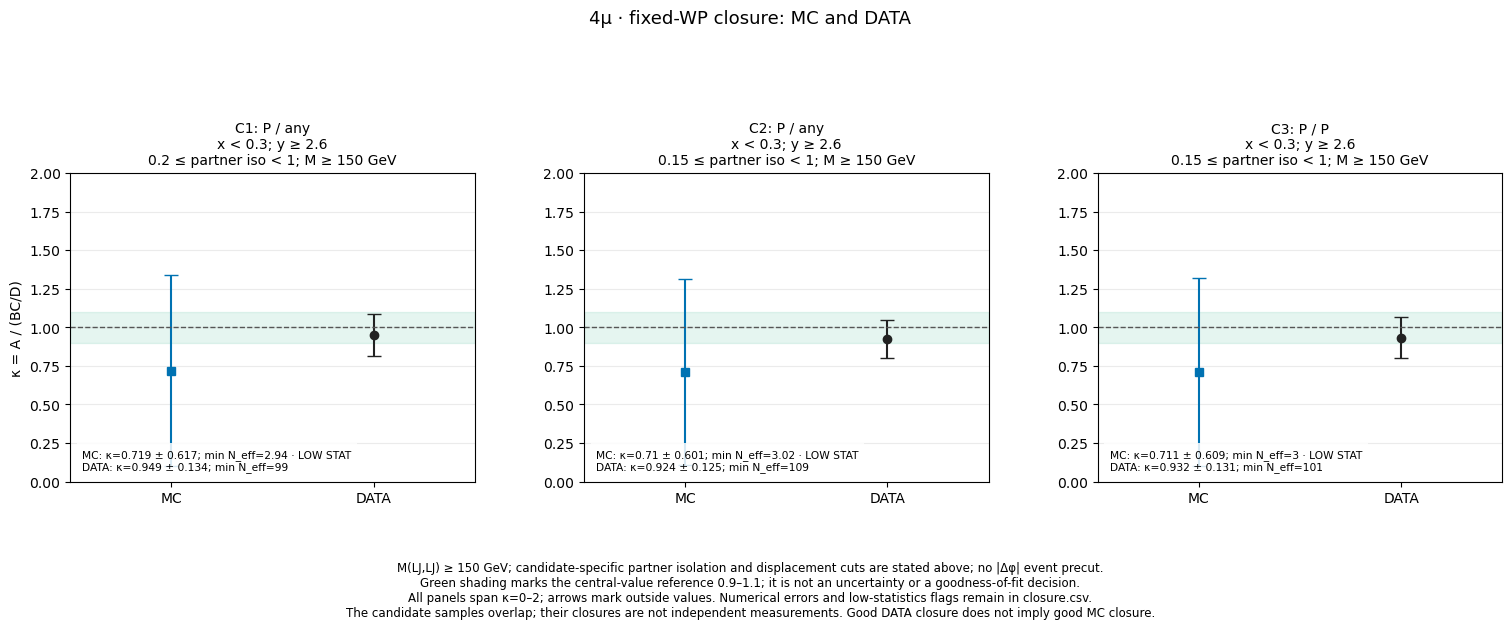

In [8]:
display(figure_lookup['combined_VR_selected_closure'])

### 4.2. 고정 WP의 ABCD별 전체 신호 최대 S/B

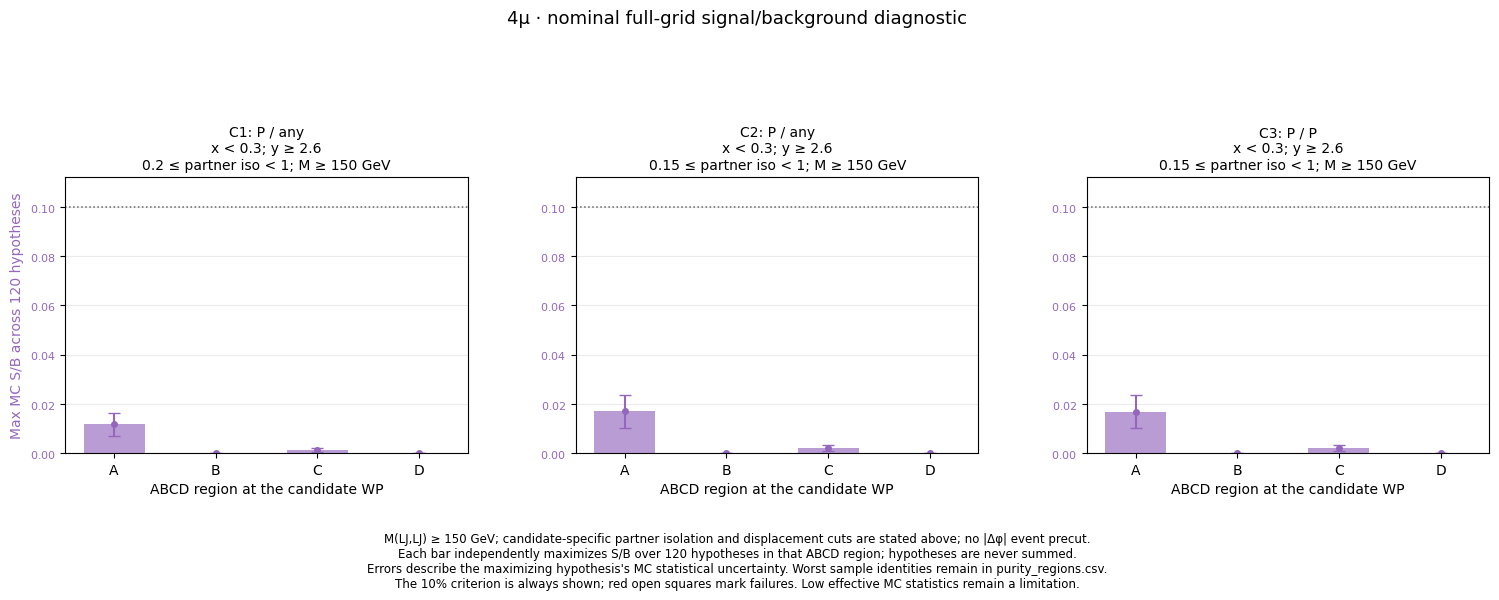

In [9]:
display(figure_lookup['mc_VR_purity_regions'])

### 4.3. DATA Mu iso–Δφ 분포

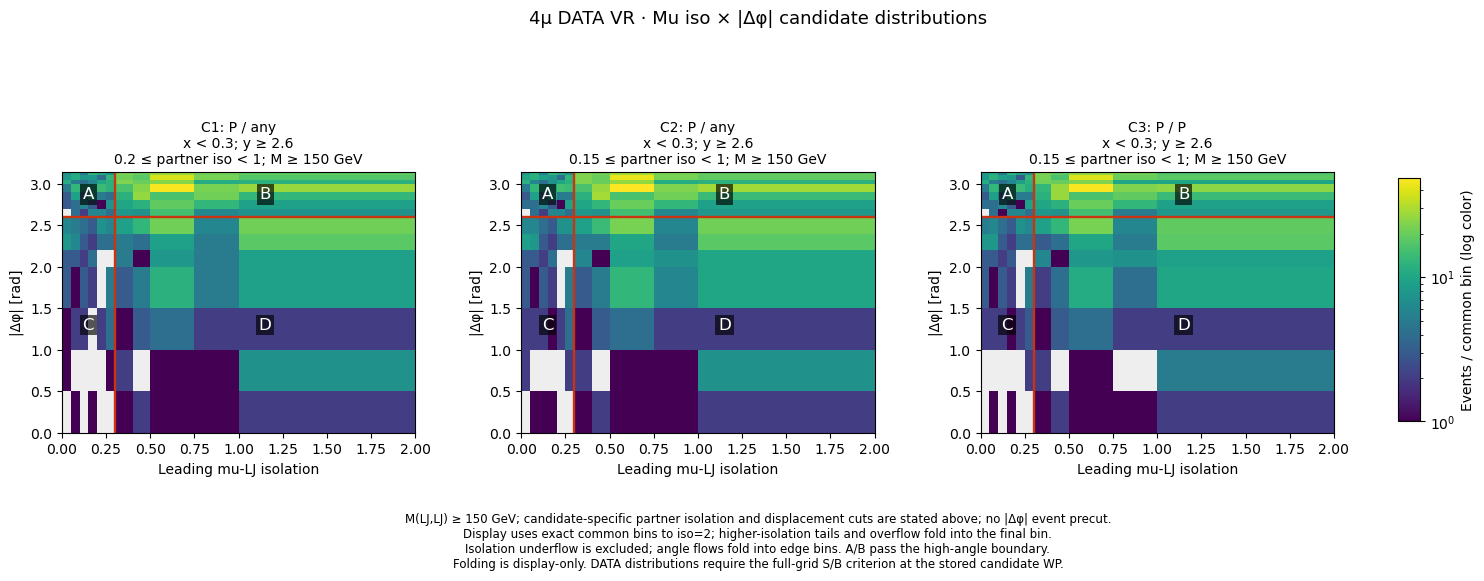

In [10]:
display(figure_lookup['data_VR_planes'])

### 4.4. DATA 고정 WP의 A·BC/D·κ

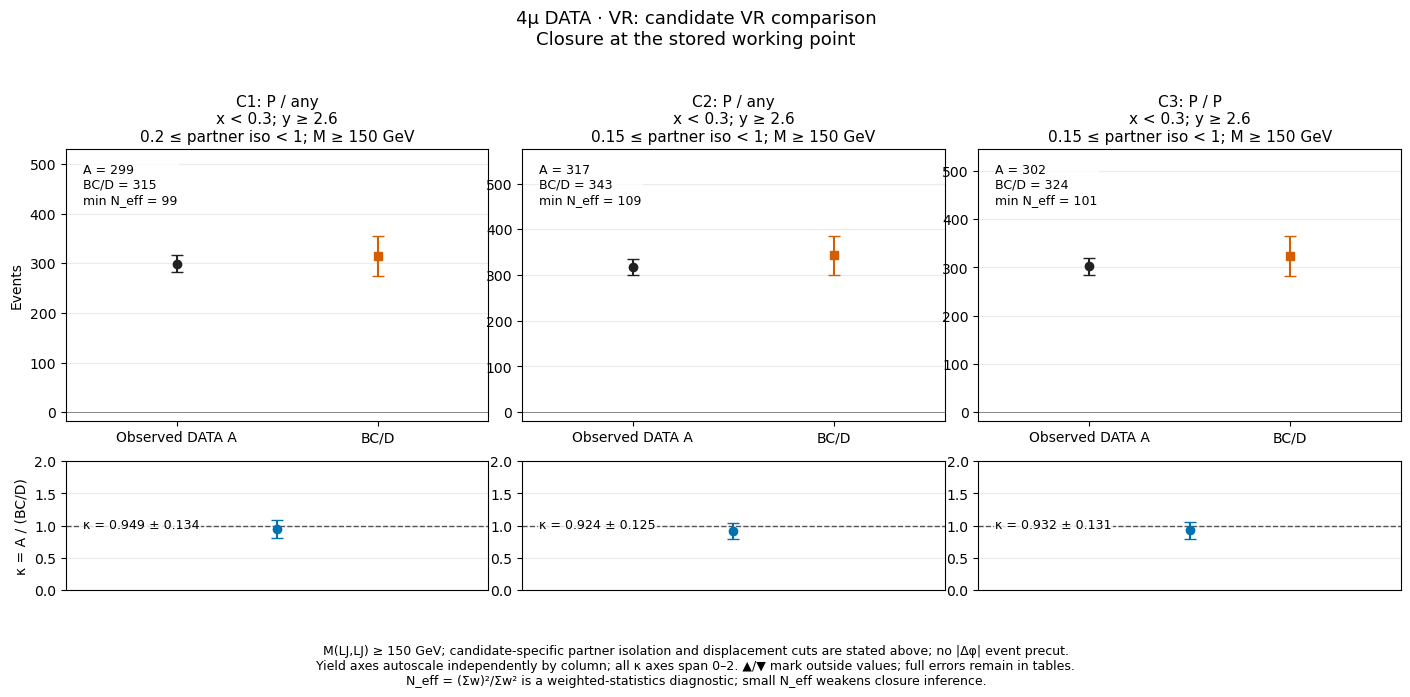

In [11]:
display(figure_lookup['data_VR_selected_closure'])

### 4.5. DATA mu isolation 경계 scan

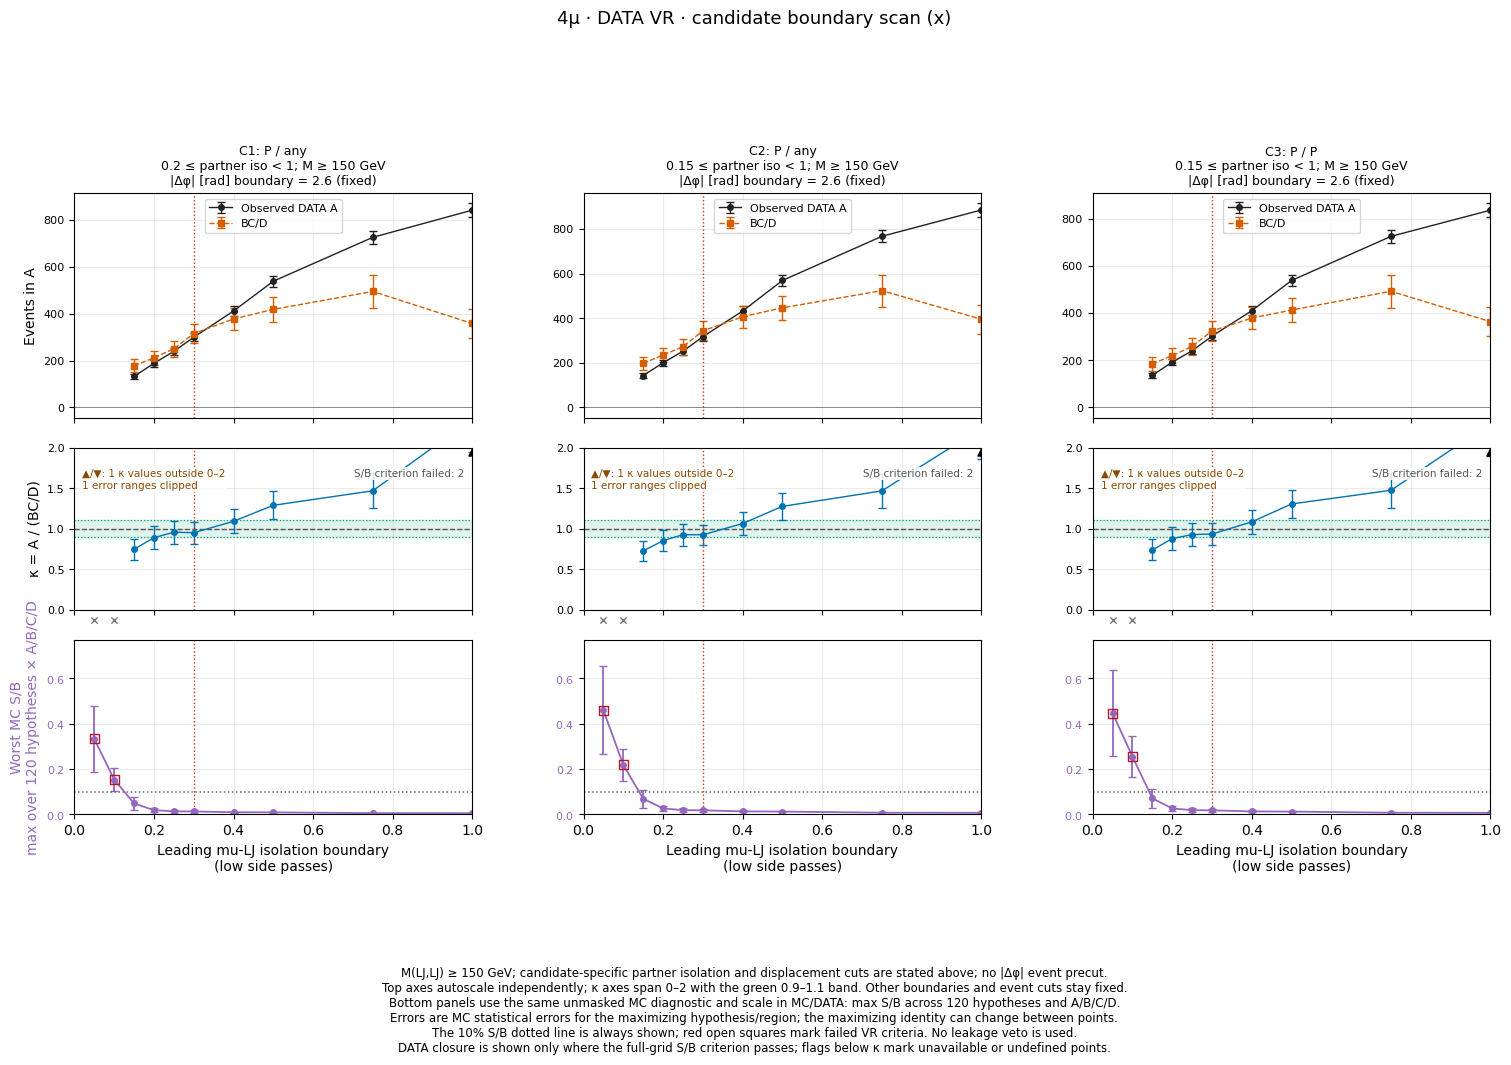

In [12]:
display(figure_lookup['data_VR_x_scan'])

### 4.6. DATA Δφ 경계 scan

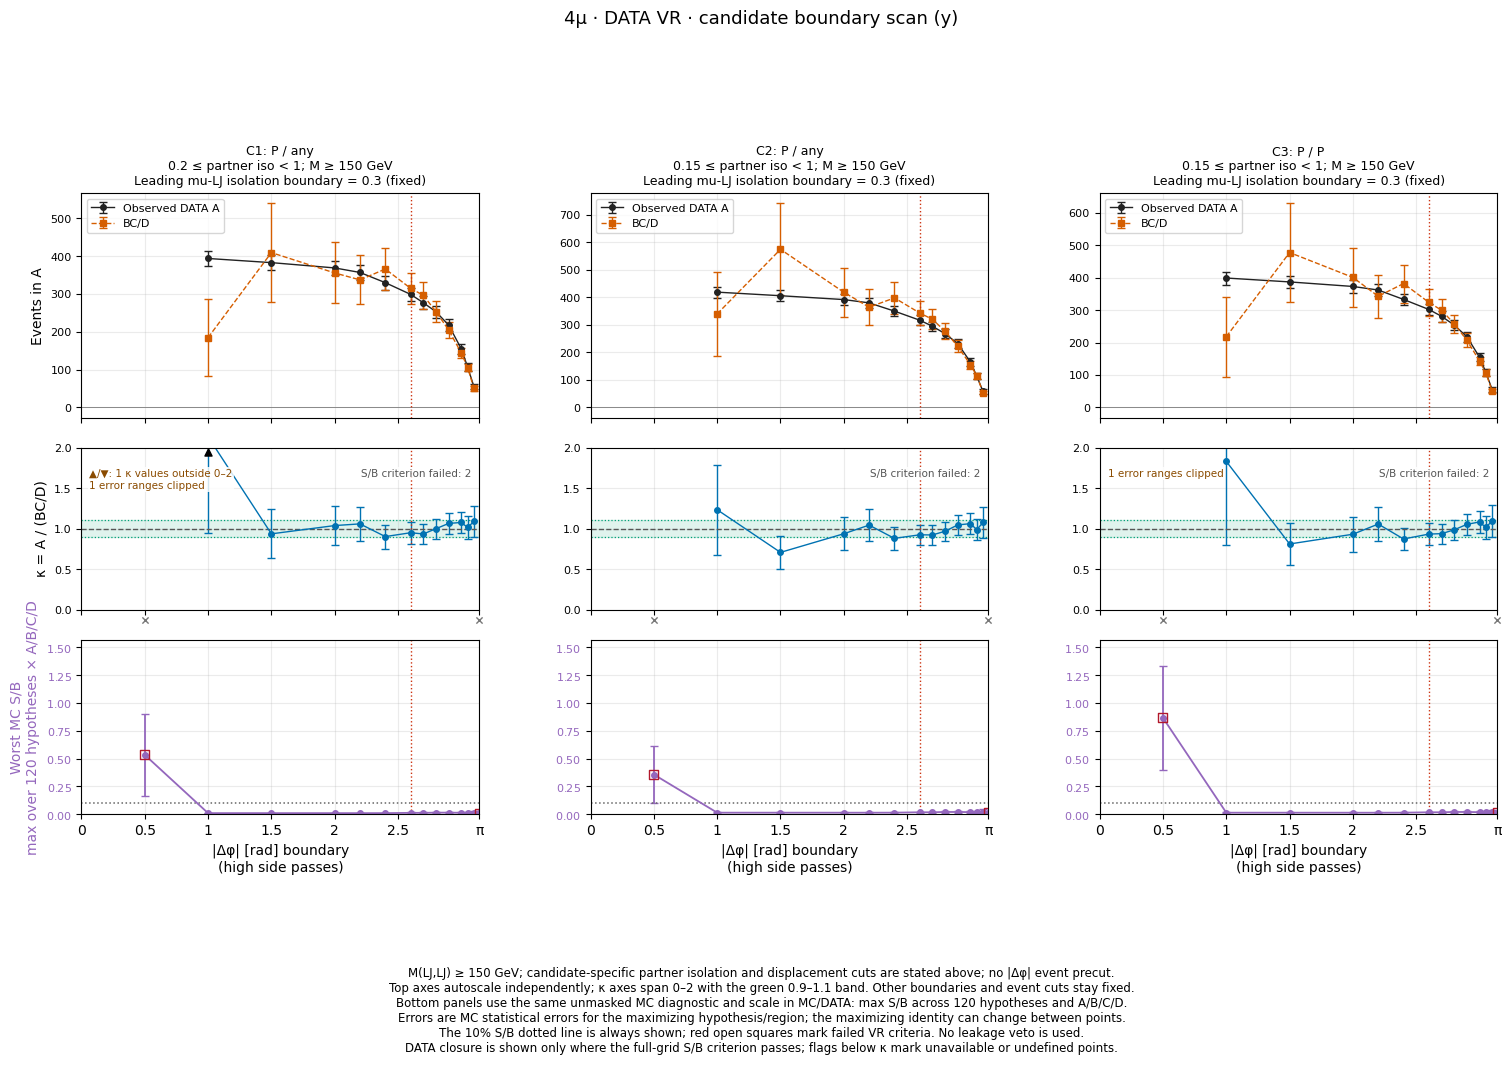

In [13]:
display(figure_lookup['data_VR_y_scan'])

### 4.7. DATA 넓은 140점 κ 지도와 선택 plateau

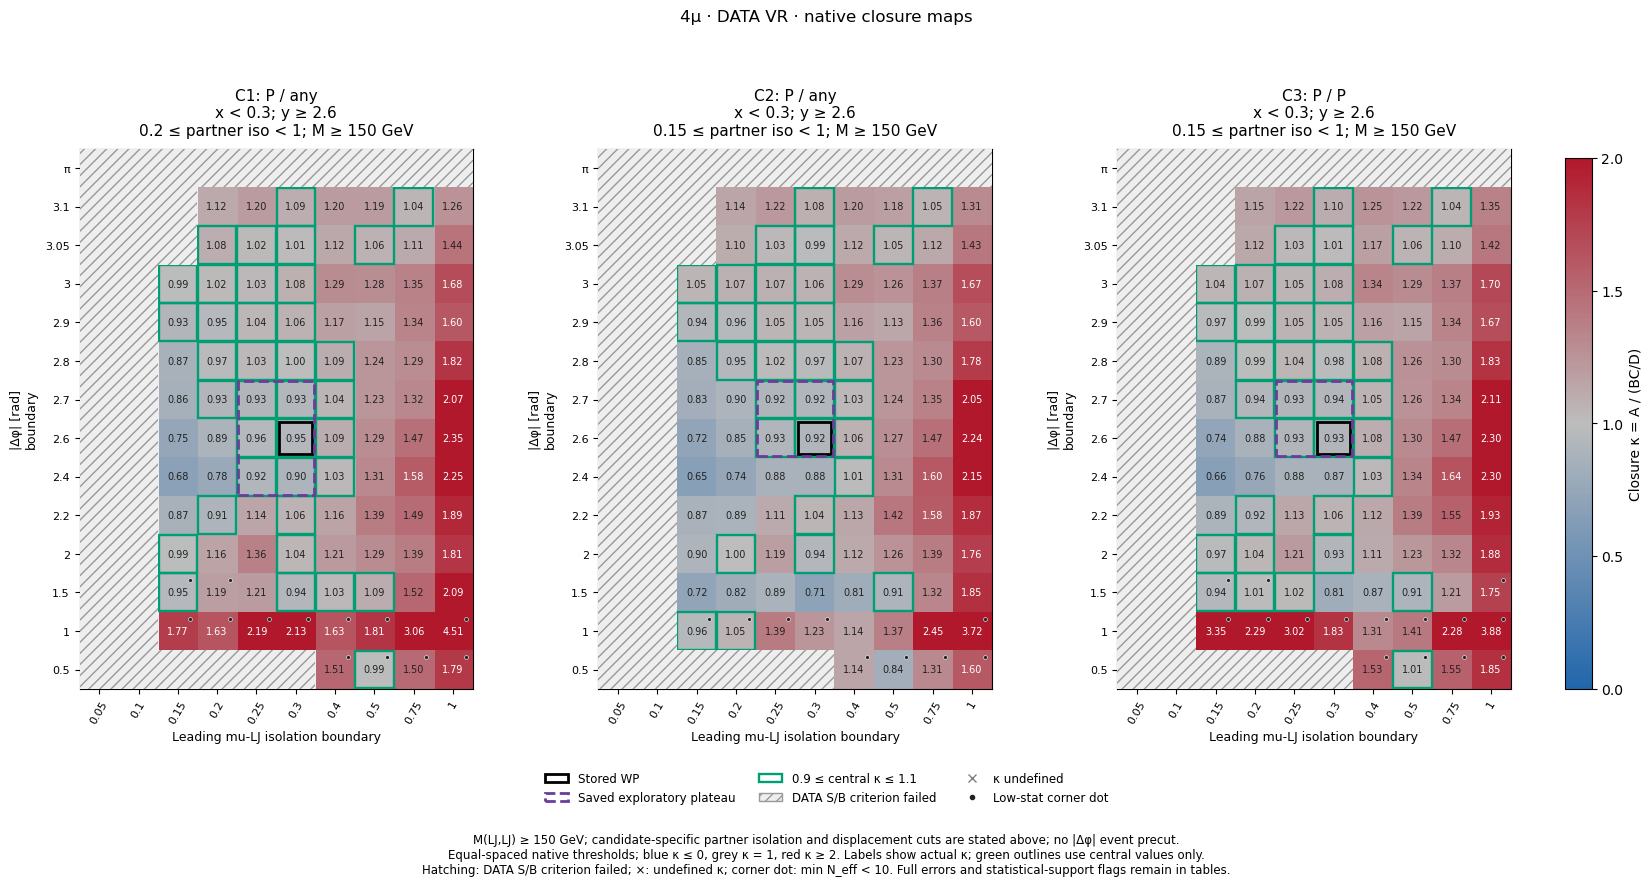

In [14]:
display(figure_lookup['data_VR_closure_grid'])

### 4.8. MC Mu iso–Δφ 분포

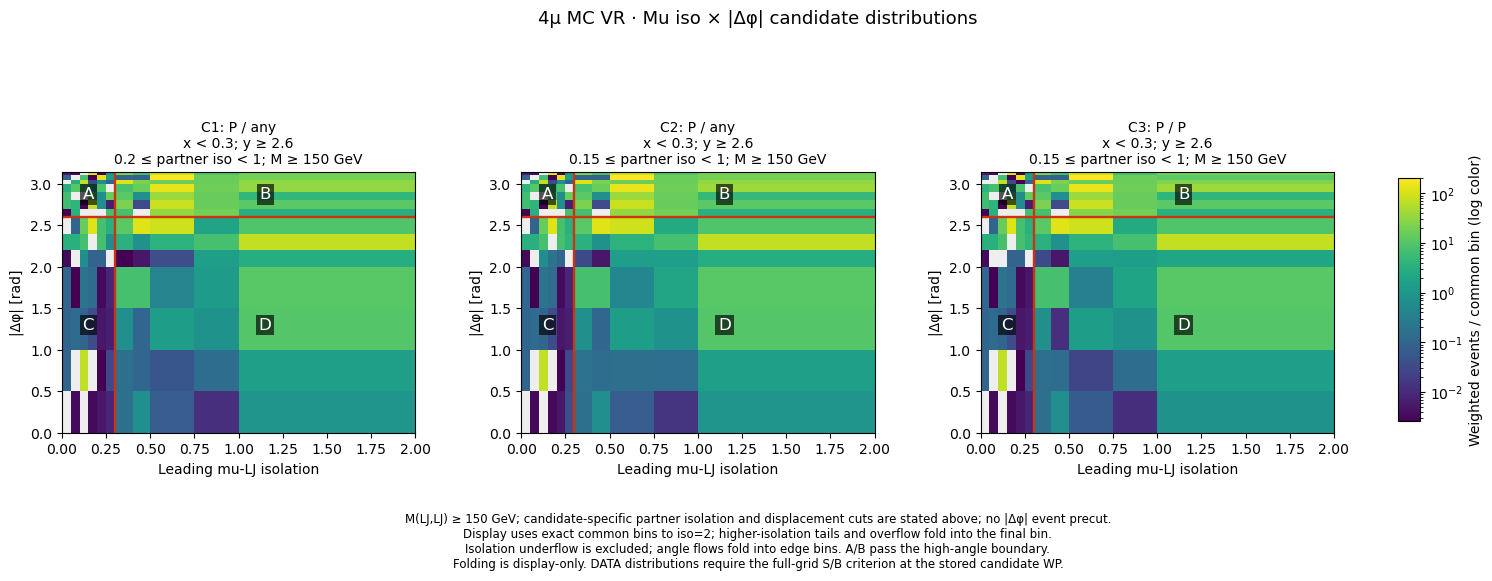

In [15]:
display(figure_lookup['mc_VR_planes'])

### 4.9. MC 고정 WP의 A·BC/D·κ

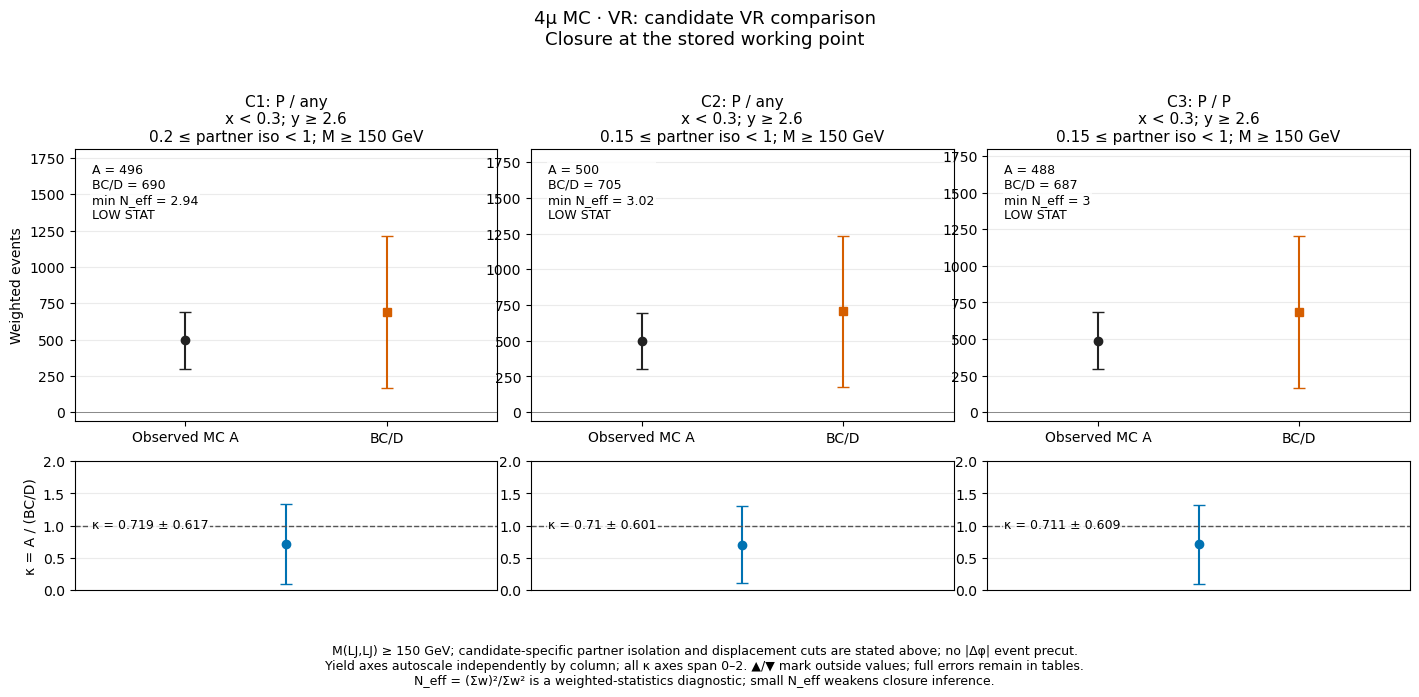

In [16]:
display(figure_lookup['mc_VR_selected_closure'])

### 4.10. MC mu isolation 경계 scan

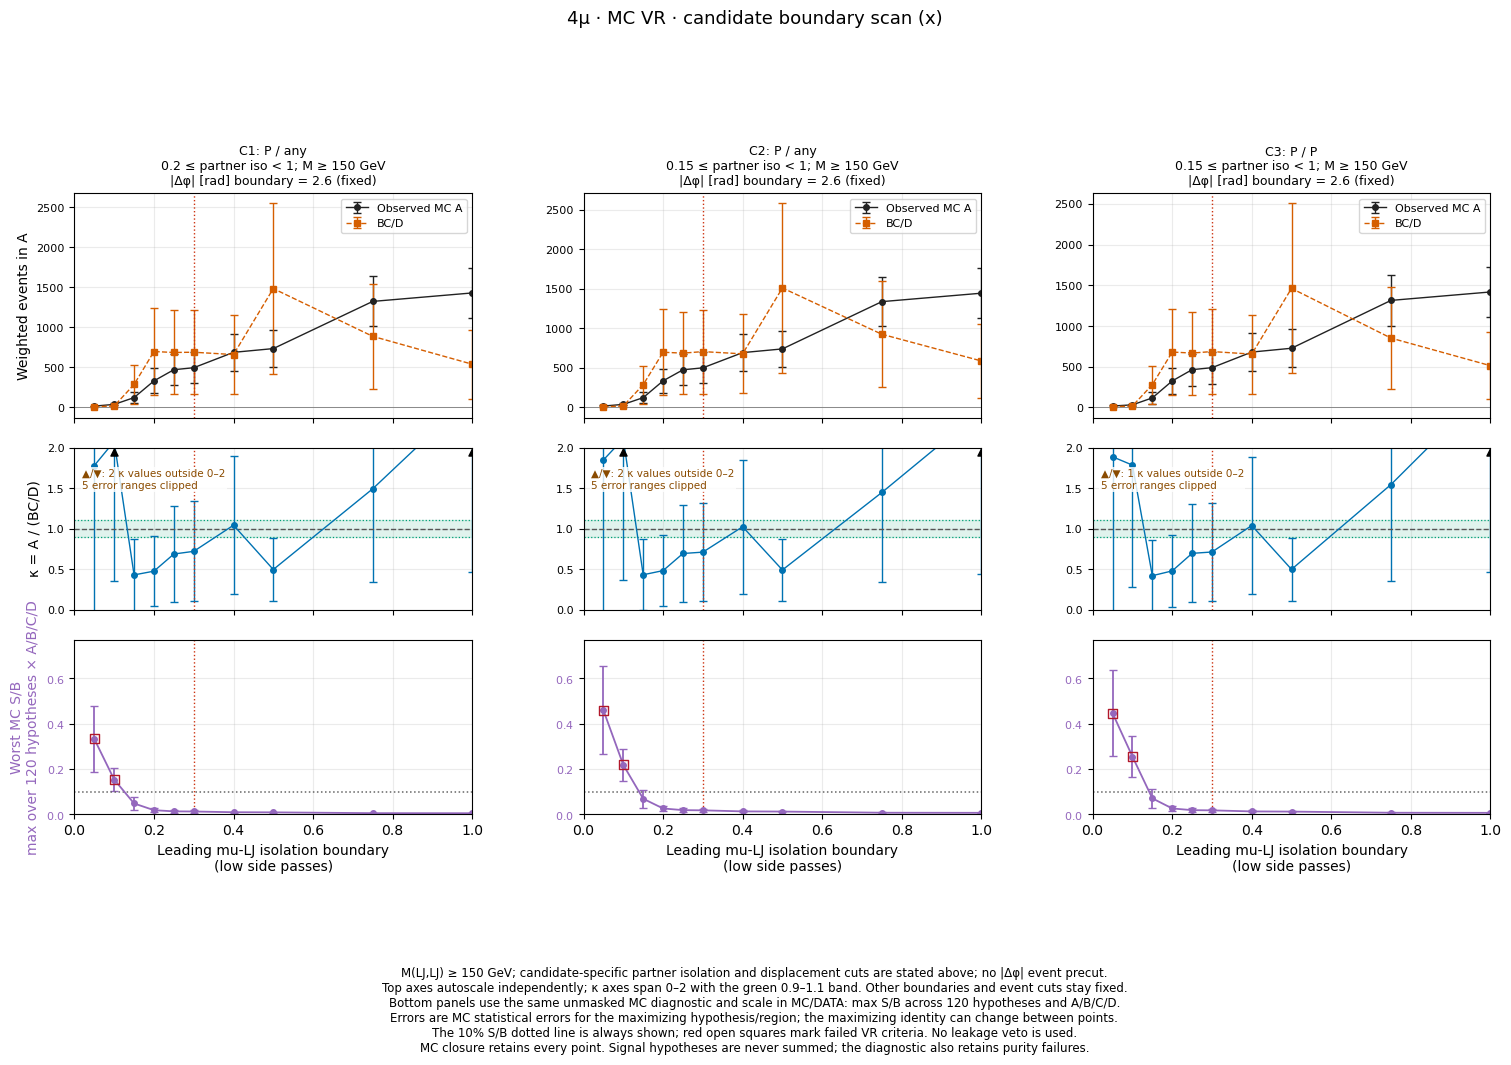

In [17]:
display(figure_lookup['mc_VR_x_scan'])

### 4.11. MC Δφ 경계 scan

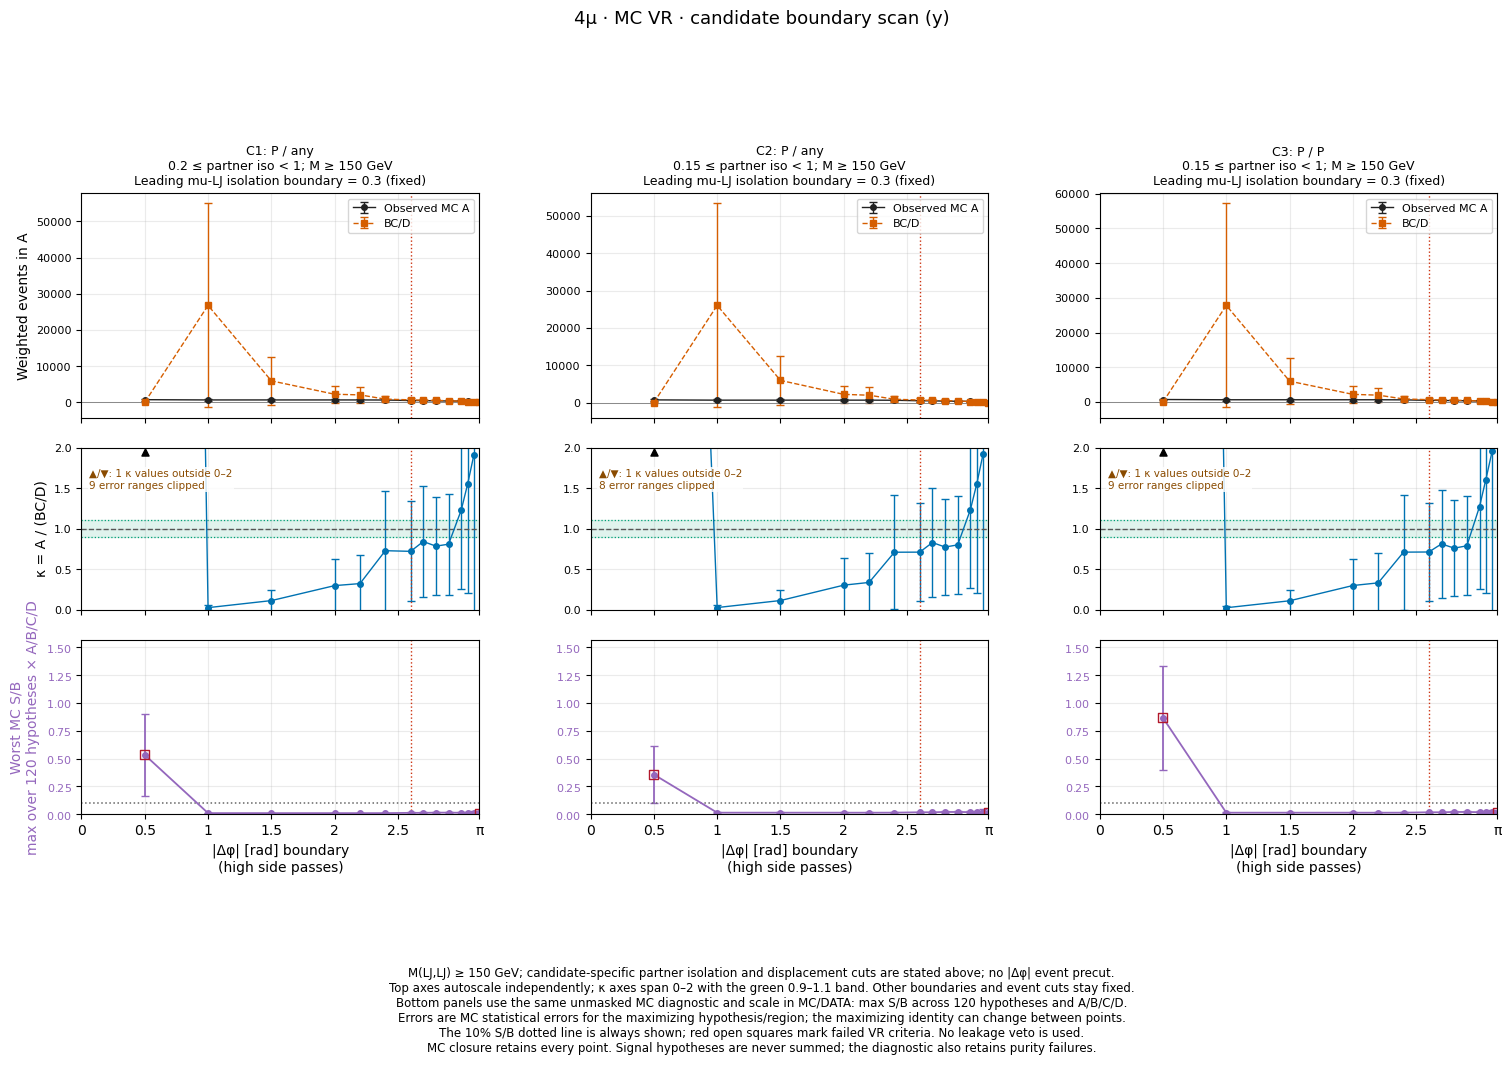

In [18]:
display(figure_lookup['mc_VR_y_scan'])

### 4.12. MC 넓은 140점 κ 지도

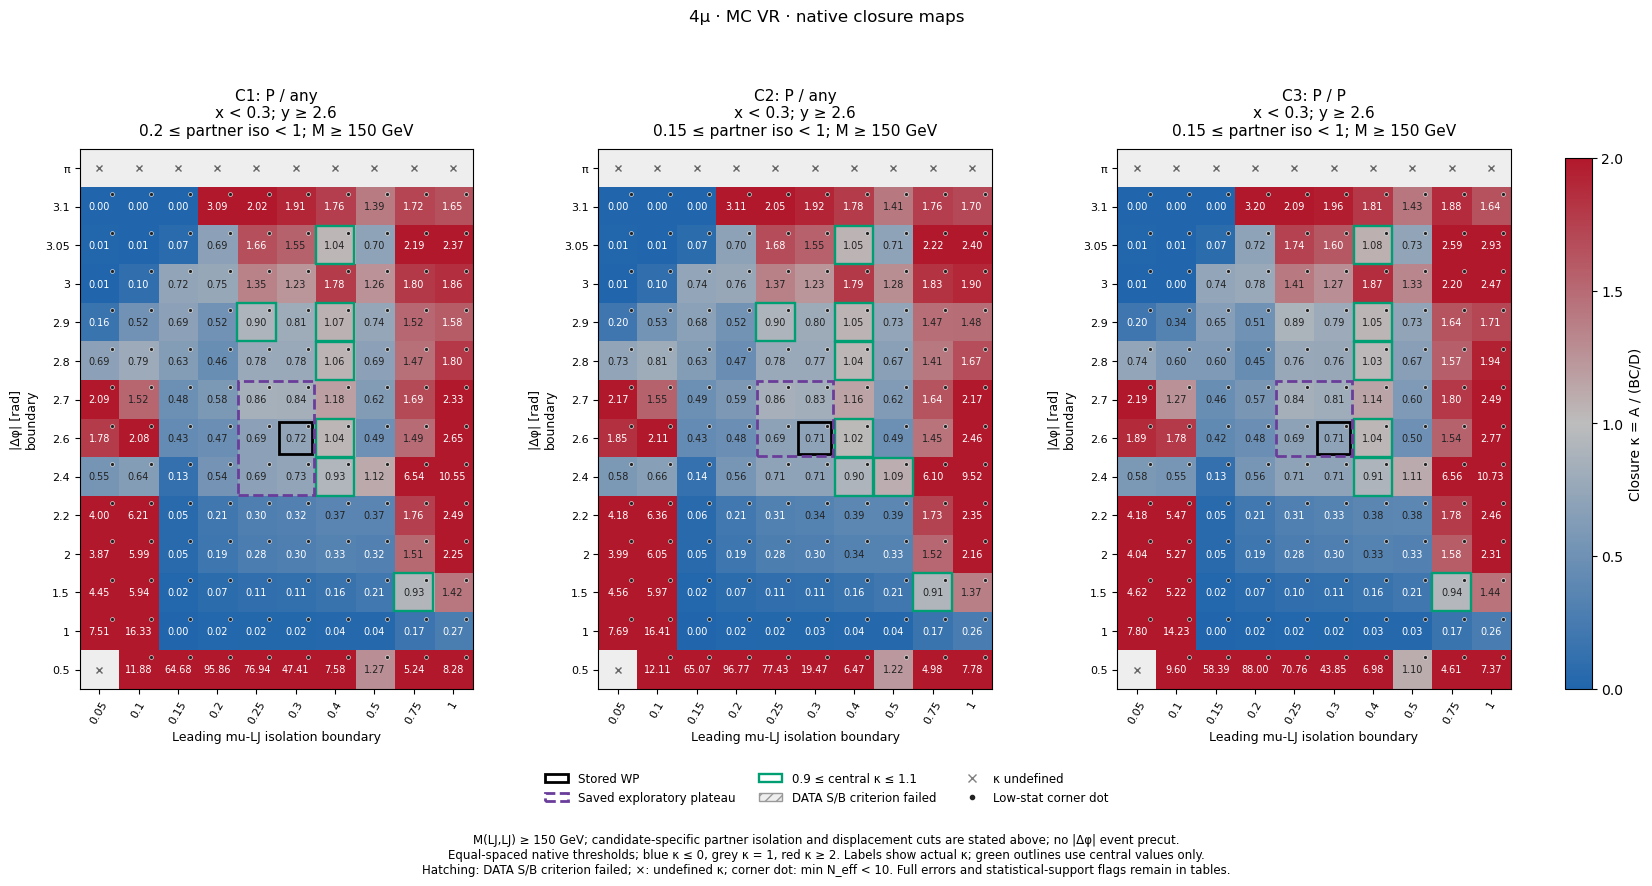

In [19]:
display(figure_lookup['mc_VR_closure_grid'])

### 4.13. MC process 조성

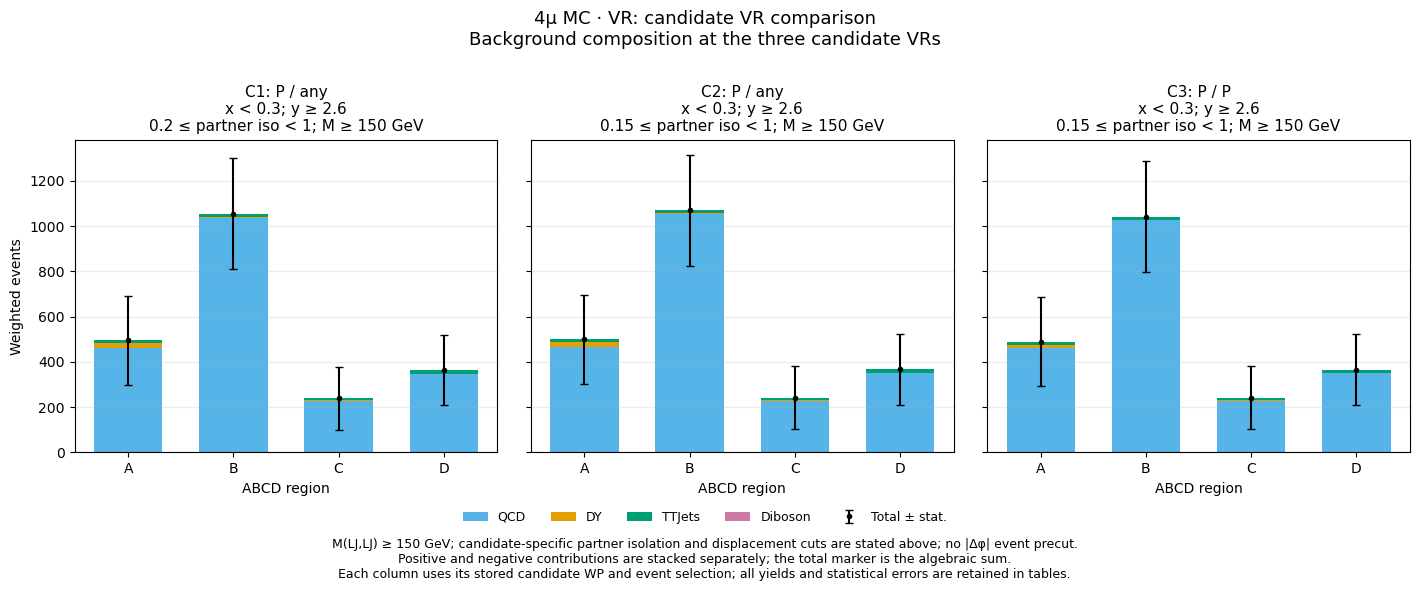

In [20]:
display(figure_lookup['mc_VR_composition'])

### 4.14. MC ABCD 유효 통계량

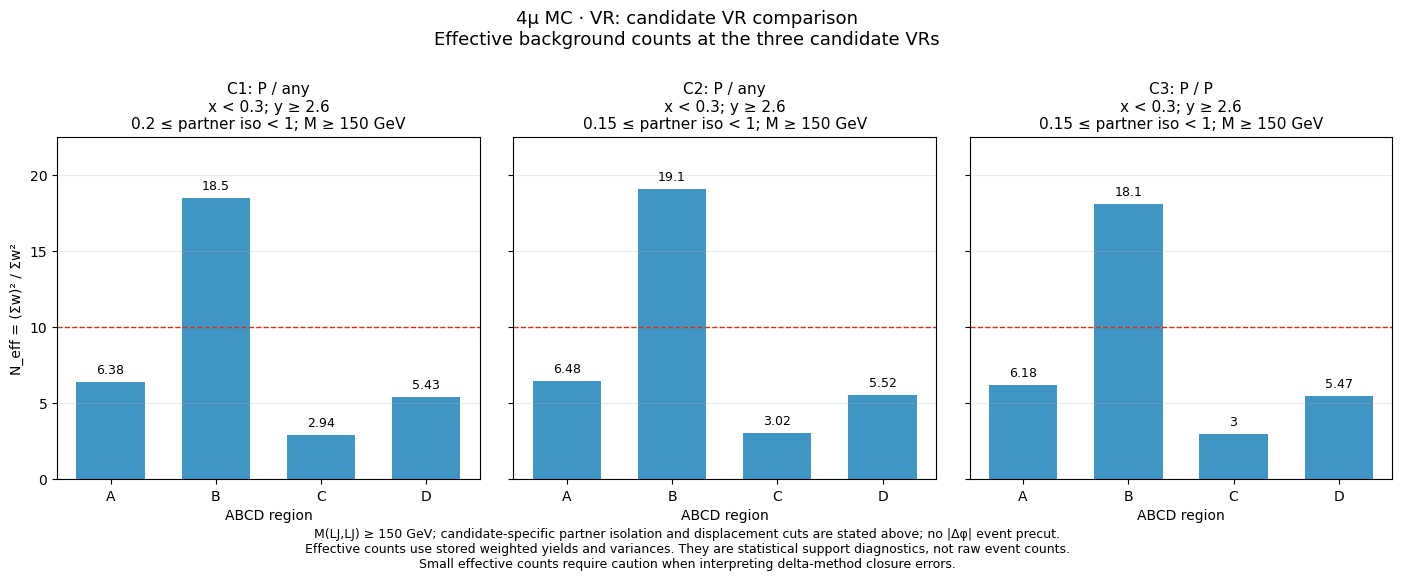

In [21]:
display(figure_lookup['mc_VR_effective_counts'])

### 4.15. DATA All/A/B/C/D 상관관계와 통계량

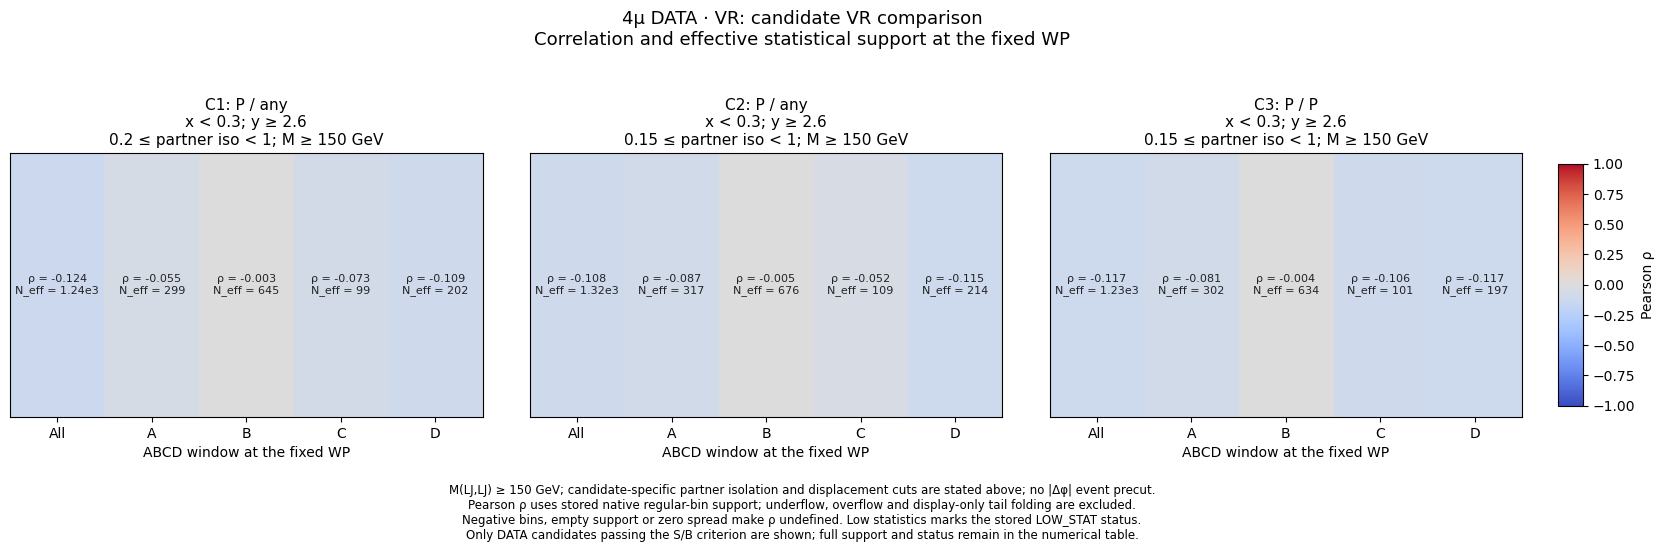

In [22]:
display(figure_lookup['data_VR_correlations'])

### 4.16. MC All/A/B/C/D 상관관계와 통계량

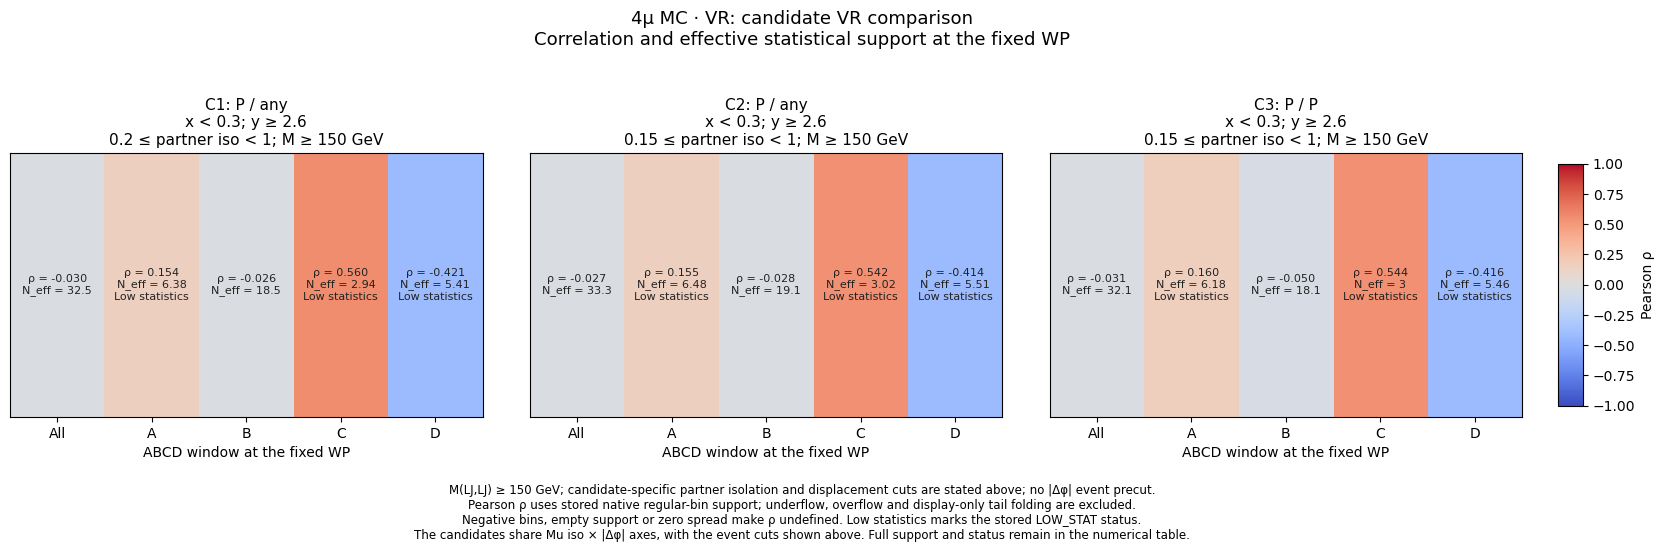

In [23]:
display(figure_lookup['mc_VR_correlations'])

## 5. Nominal MC SR 참고

기존 11·12의 **DD, M≥150 GeV, 0≤partner iso<0.5** 선택을 공통 참고로 사용한다.
고정 WP는 **(mu iso, Δφ)=(0.30,2.6)**이며, 후보 VR의 질량·partner isolation·WP를 상속하지 않는다.
따라서 low-mass 4mu VR의 iso=0.50 WP와도 구분된다. 별도 Δφ event precut은 없다.

MC SR의 분포·고정 WP closure·넓은 1D/2D scan을 표시한다. S/B=10%는 참고선이며 MC SR을 가리는 조건이 아니다.
SR에 대한 DATA 수치는 계산하지 않는다. 11·12에 저장된 MC SR closure·1D scan·2D grid 수치를 재현하는지 검산한다.
각 후보와 독립된 공통 SR 하나이므로 한 열로 보여준다.

In [24]:
with pd.option_context('display.max_columns', None):
    display(tables['sr_reference_selection'])
    display(tables['sr_reference_closure'][['plane', 'source', 'context', 'tx', 'ty', 'A', 'B', 'C', 'D',
                                          'pred', 'pred_error', 'kappa', 'kappa_error', 'neff_min', 'status']])
print('MC SR 회귀 검사:', len(tables['sr_reference_regression']), '개 / 통과:',
      bool(tables['sr_reference_regression'].passed.all()))


,plane,state0,state1,partner_iso_low,partner_iso_high,mass_low,mass_high,tx,ty,plateau_mu_iso,plateau_abs_dphi,kind,label,selection,x_label,y_label
0,SR,D,D,0.0,0.5,150.0,None,0.3,2.6,[],[],mu_dphi,Nominal MC SR: D / D,0 ≤ partner iso < 0.5; M ≥ 150 GeV,Leading mu-LJ isolation,|Δφ| [rad]


,plane,source,context,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,status
76,SR,MC,SR,0.3,2.6,3.253182,0.72817,0.002571,0.892088,0.002099,0.003244,1550.183866,2852.868948,1.0,LOW_STAT_SIDEBAND


MC SR 회귀 검사: 1513 개 / 통과: True


### 5.1. MC SR Mu iso–Δφ 분포

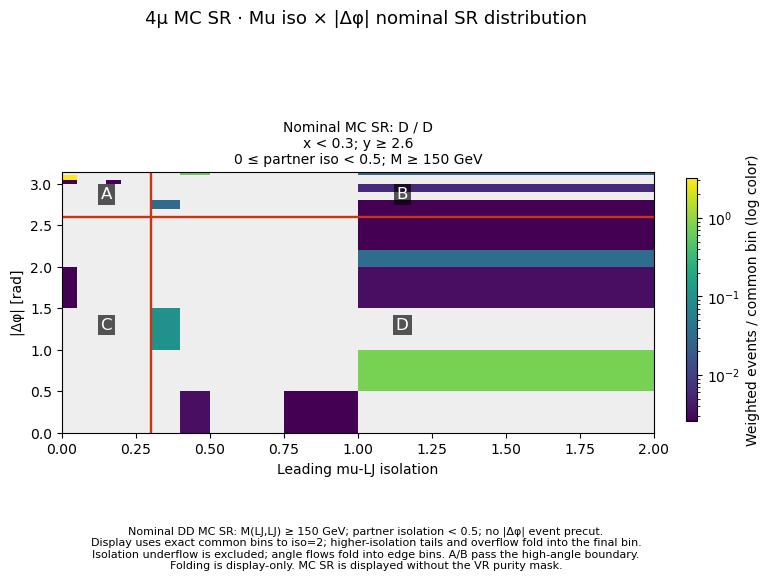

In [25]:
display(figure_lookup['mc_SR_planes'])

### 5.2. MC SR 고정 WP의 A·BC/D·κ

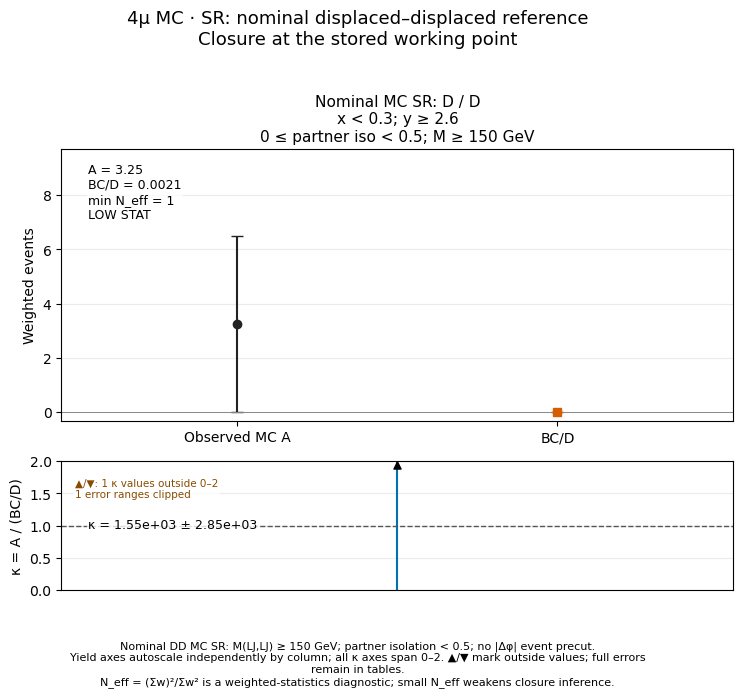

In [26]:
display(figure_lookup['mc_SR_selected_closure'])

### 5.3. MC SR mu isolation 경계 scan

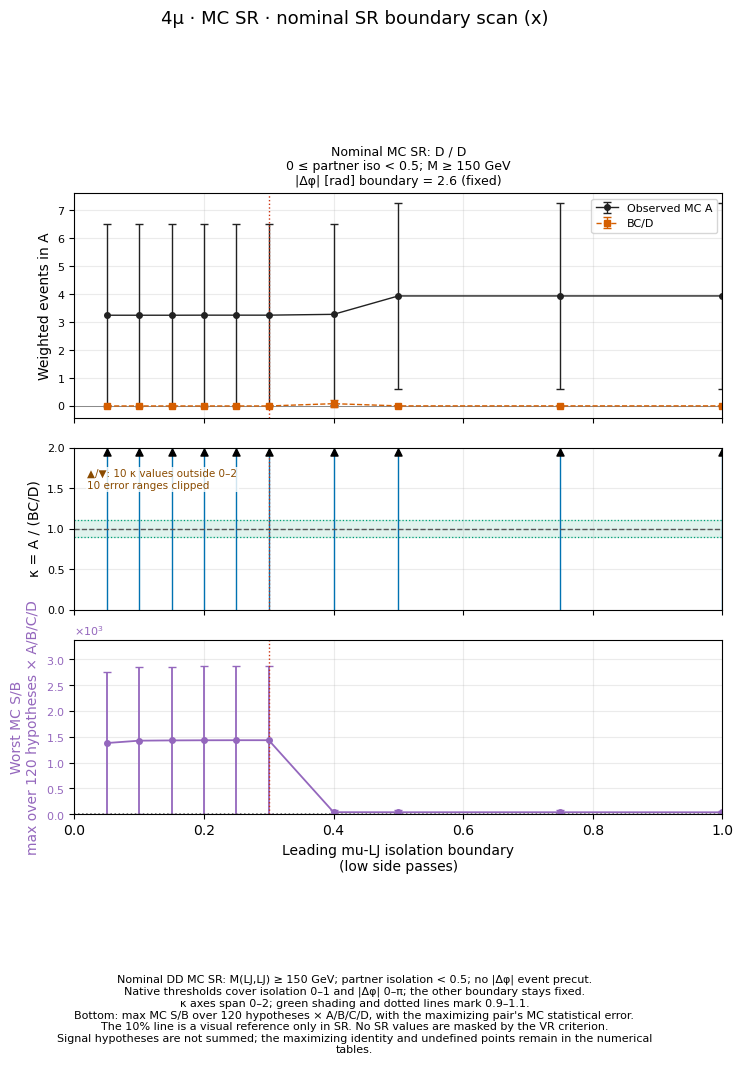

In [27]:
display(figure_lookup['mc_SR_x_scan'])

### 5.4. MC SR Δφ 경계 scan

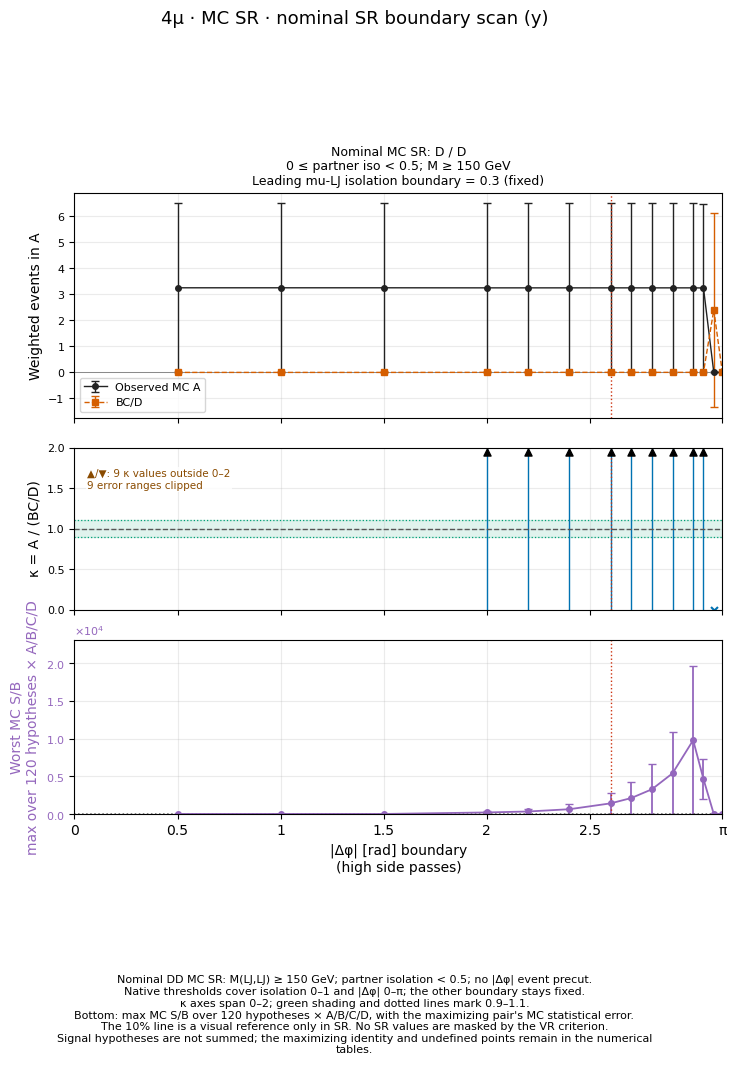

In [28]:
display(figure_lookup['mc_SR_y_scan'])

### 5.5. MC SR 넓은 140점 κ 지도

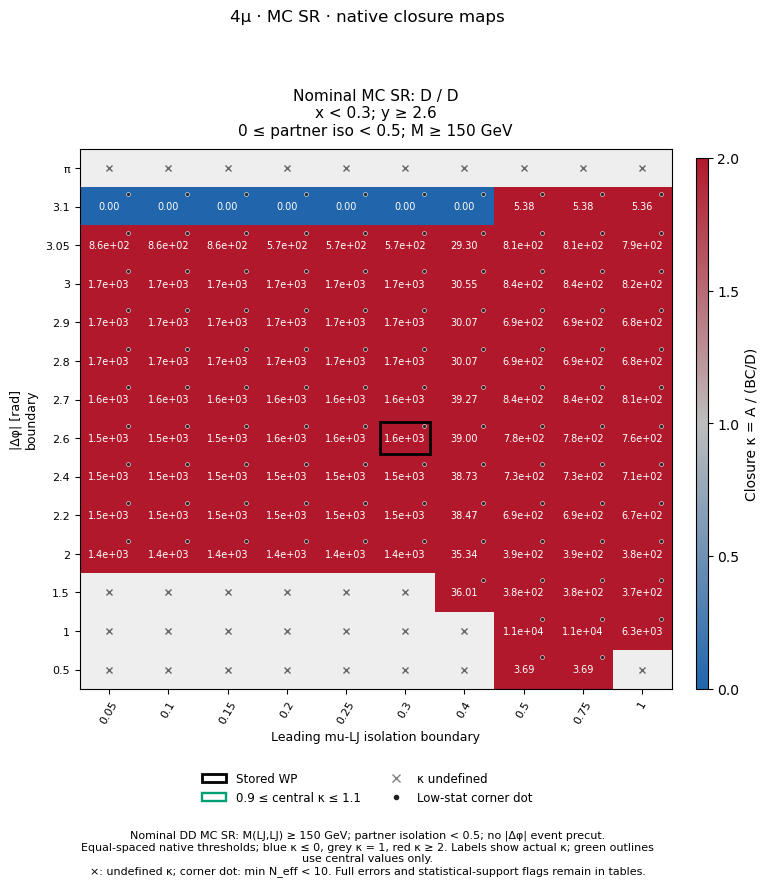

In [29]:
display(figure_lookup['mc_SR_closure_grid'])

## 6. 전체 신호·plateau 수치와 내보내기

`purity_regions`에는 nominal WP의 ABCD별 최대 S/B·MC 통계오차·최악 신호가 들어 있다.
`signal_points.csv`에는 모든 후보·140개 WP·120개 신호 가설의 ABCD yield/sumw²/S/B가 기록된다.
`sr_reference_*.csv`에는 별도 MC SR의 선택·closure·scan·grid·신호 진단·회귀 결과가 기록된다.
PNG/PDF, 전체 슬라이드 PDF, MC/DATA summary·scan·composition·상관관계·회귀·입력 SHA256 표를 전용 outputs 폴더에 저장한다.

In [30]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', 80):
    display(tables['purity_regions'])
    display(tables['grid'].loc[tables['grid'].source.eq('DATA'),
                              ['plane', 'tx', 'ty', 'kappa', 'kappa_error', 'max_S_B',
                               'approved', 'point_pass', 'in_plateau', 'neff_min']])
export_candidate_comparison(results, CONFIG, figures)
display(tables['figure_manifest'])
display(Markdown(f'[전체 summary 슬라이드 PDF]({OUTPUT_DIR.name}/comparison_slides.pdf)'))


,plane,context,tx,ty,region,max_S_B,max_S_B_error,worst_sample,approved
0,C1,VR,0.3,2.6,A,0.011801,0.004680,4Mu_800GeV_5p0GeV_0p05mm,True
1,C1,VR,0.3,2.6,B,0.000025,0.000011,4Mu_800GeV_5p0GeV_0p05mm,True
2,C1,VR,0.3,2.6,C,0.001385,0.000819,4Mu_800GeV_5p0GeV_0p05mm,True
3,C1,VR,0.3,2.6,D,0.000009,0.000010,4Mu_800GeV_5p0GeV_0p05mm,True
4,C2,VR,0.3,2.6,A,0.016929,0.006659,4Mu_800GeV_5p0GeV_0p05mm,True
5,C2,VR,0.3,2.6,B,0.000037,0.000014,4Mu_800GeV_5p0GeV_0p05mm,True
6,C2,VR,0.3,2.6,C,0.002116,0.001229,4Mu_800GeV_5p0GeV_0p05mm,True
7,C2,VR,0.3,2.6,D,0.000010,0.000011,4Mu_800GeV_5p0GeV_0p5mm,True
8,C3,VR,0.3,2.6,A,0.016844,0.006782,4Mu_800GeV_5p0GeV_0p05mm,True
9,C3,VR,0.3,2.6,B,0.000038,0.000014,4Mu_800GeV_5p0GeV_0p05mm,True


,plane,tx,ty,kappa,kappa_error,max_S_B,approved,point_pass,in_plateau,neff_min
140,C1,0.05,0.500000,NaN,NaN,0.287456,False,False,False,NaN
141,C1,0.05,1.000000,NaN,NaN,0.288676,False,False,False,NaN
142,C1,0.05,1.500000,NaN,NaN,0.288909,False,False,False,NaN
143,C1,0.05,2.000000,NaN,NaN,0.288227,False,False,False,NaN
144,C1,0.05,2.200000,NaN,NaN,0.310104,False,False,False,NaN
...,...,...,...,...,...,...,...,...,...,...
835,C3,1.00,2.900000,1.673029,0.282330,0.006758,True,False,False,70.0
836,C3,1.00,3.000000,1.703647,0.316085,0.007108,True,False,False,45.0
837,C3,1.00,3.050000,1.418041,0.286764,0.007941,True,False,False,35.0
838,C3,1.00,3.100000,1.352053,0.366819,0.011133,True,False,False,17.0


저장: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/14_C1_C3_4mu_VR_summary_outputs


,figure,png,pdf
0,mc_VR_planes,mc_VR_planes.png,mc_VR_planes.pdf
1,data_VR_planes,data_VR_planes.png,data_VR_planes.pdf
2,mc_VR_selected_closure,mc_VR_selected_closure.png,mc_VR_selected_closure.pdf
3,data_VR_selected_closure,data_VR_selected_closure.png,data_VR_selected_closure.pdf
4,mc_VR_x_scan,mc_VR_x_scan.png,mc_VR_x_scan.pdf
5,mc_VR_y_scan,mc_VR_y_scan.png,mc_VR_y_scan.pdf
6,data_VR_x_scan,data_VR_x_scan.png,data_VR_x_scan.pdf
7,data_VR_y_scan,data_VR_y_scan.png,data_VR_y_scan.pdf
8,mc_VR_closure_grid,mc_VR_closure_grid.png,mc_VR_closure_grid.pdf
9,data_VR_closure_grid,data_VR_closure_grid.png,data_VR_closure_grid.pdf


[전체 summary 슬라이드 PDF](14_C1_C3_4mu_VR_summary_outputs/comparison_slides.pdf)

## 해석 범위

C1⊂C2, C3⊂C2이며 C1과 C3도 겹친다. 4mu 후보의 MC 유효통계가 작다는 한계를 함께 본다.

좋은 DATA closure가 좋은 MC closure를 뜻하지 않는다. 후보 선정에는 DATA 안정성과 MC S/B를 각각 사용했으며,
MC closure 불일치·MC 저통계를 숨기지 않는다. 서로 겹치는 후보를 독립 VR 세 개처럼 합치지 않는다.
이 노트북은 저장된 후보를 요약하며, 새 WP 최적화나 최종 분석 선택을 수행하지 않는다.